# Book and audiobook market research
### Public audience evidence, industry revenue and company coverage

A reproducible companion to the Global Reading Atlas dashboard. This notebook uses the **same
cached observations**, retains editable Python plotting code, and checks its shared tables against
the dashboard snapshot. It makes no network request and uses no Storytel internal data.

**Scope:** audiobook listening, paper-book reading, genre preferences, industry sales and revenue, and public
company information across countries. The company inventory is an initial reviewed set, not a
complete worldwide census. Revenue and audience participation answer different questions.

**Case study:** Storytel new-market entry and existing-market growth are separate research tracks.
Both need commercial evidence beyond public demand surveys.

**Requested period:** 2022 through the current evidence refresh. Source publication dates and
observation years remain distinct. The older US phone-survey history is a labelled background check.

## Evidence at a glance

- **Industry-wide coverage includes 23 reviewed companies and services**, monetary industry evidence for 29 countries,
  and annual survey waves of daily paper, ebook and audiobook reach in
  Norway and Sweden.
  Company rows include parent/brand overlap and cannot be summed into market share.
- **9 countries have reviewed listening observations.** The inventory includes
  annual participation, weekly listening, daily reach and listening within reader subsets.
  Each source retains its own population, question and recall period; a larger inventory is not a matched country ranking.
- **As historical background, US audiobook participation moved from 11% in 2011 to
  23% in 2021** during the phone-survey period. The
  **26% result in 2025** uses a different survey mode and stands separately.
- **Canada supplies format-specific catalogue hypotheses for one explicitly selected survey year.**
  The `GENRE_YEAR` parameter defaults to the latest reviewed wave. The selected-year leaders and
  percentages are calculated below. The audited 2024 baseline remains available; genre years are never pooled.
  Exact genre-subgroup sample sizes are unpublished.
- **The 2026 Story Report adds a common-question view of genres and listening occasions across
  five existing markets.** These percentages describe listener preferences, not national adoption
  or paid subscription penetration. Only each country's top five responses are published.
- **These data support research prioritisation for two separate tracks:** new entry and growth in
  existing markets. They cannot identify the best investment country without verified operating
  footprint, language/catalogue rights, addressable paying audience, competition, price,
  acquisition cost and retention evidence.

Use source-specific profiles and the country evidence table below. Percentages are never converted
into total listeners or averaged into a country attractiveness score.

## Context & Methods

Audio is the primary metric in this notebook. Eurostat's total book participation includes
audiobooks, but does not isolate them, so it supplies no audiobook adoption estimate here.

| Evidence family | What the metric answers | What it cannot answer |
|:--|:--|:--|
| US annual adult participation | Share of surveyed adults listening in the prior year | Paid subscription penetration or current revenue |
| Canada / Singapore annual reader subsets | Listening use within the stated reader base | Share of all residents listening |
| Norway / Sweden average-day reach | Listening on an average day within each population scope | Annual participation or repeat listening frequency |
| Weekly listening and other national survey windows | Use within the exact stated population and recall period | Annual participation when the question is weekly or year to date |
| Source-specific genre questions | Selected genres among each reported survey base | Catalogue market share, national adoption or listening hours |

### Key Assumptions

1. Published percentages are stored on a **0–100 scale**. A difference is in percentage points.
2. Periods, population scopes and denominators remain visible. Equal axis scales help read each
   observation, but do not make the surveys comparable. Annual reader subsets differ from one another.
3. The US 2011–2021 phone-survey series and 2025 web/phone survey observation stay separate.
   The notebook does not treat the later difference as measured growth across methods.
4. Format use and genre selections overlap. The Canadian genre questions allow up to three selections;
   missing values remain missing, and percentages need not total 100%.
5. Singapore's genre question covers mixed reading materials and all reading formats. It does not
   isolate audiobook genres. The notebook keeps it out of the audio catalogue charts.
6. Aggregate public tables do not provide respondent microdata or survey-design intervals here.
   There are no inferred confidence intervals, causal effects or significance tests.
7. The candidate-country list below is a user research filter. Storytel-brand presence and
   Storytel-group presence are different questions, so verify both before treating a country as a new-entry candidate.
8. The Storytel-commissioned April 2026 online-panel study covers adults age 18–79 across five
   countries (5,077 total respondents). Its listener-subgroup eligibility and exact base sizes,
   weighting details and response instructions are unpublished. The overall sample is not the
   denominator for listener preference percentages; unlisted top-five responses remain unreported.

| Decision track | Demand question | Required business evidence |
|:--|:--|:--|
| New entry | Does a defined local audience listen and show willingness to pay? | Verified footprint, local rights, price, competition, acquisition and launch costs |
| Existing-market growth | Which audience or catalogue opportunity can improve profitable growth? | Local paying penetration, segment conversion, retention, catalogue gaps and marginal contribution |

### 1. Set up Python

In your notebook editor, open this notebook and select the project's `.venv` interpreter. Run all cells in order.
Inputs are found from any directory inside the project. No user-level kernel registration is required.

In [1]:
from pathlib import Path
import os
import json
import hashlib
import textwrap
from importlib.metadata import version

def find_project_root():
    explicit = os.environ.get("GRA_PROJECT_ROOT")
    candidates = ([Path(explicit)] if explicit else []) + [Path.cwd(), *Path.cwd().parents]
    for candidate in candidates:
        if (candidate / "data/processed/format_profiles.csv").is_file():
            return candidate.resolve()
    raise FileNotFoundError("Start inside Global Reading Atlas or set GRA_PROJECT_ROOT.")

ROOT = find_project_root()
OUTPUT_ROOT = Path(os.environ.get("GRA_NOTEBOOK_OUTPUT_ROOT", ROOT)).resolve()
FIGURES = OUTPUT_ROOT / "outputs/audiobook_figures"
FIGURES.mkdir(parents=True, exist_ok=True)
os.environ.setdefault("MPLCONFIGDIR", str(OUTPUT_ROOT / "work/matplotlib"))

import numpy as np
import pandas as pd
import matplotlib
matplotlib.use("module://matplotlib_inline.backend_inline")
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter
from IPython.display import display, HTML, Markdown

plt.rcParams.update({
    "font.family": "DejaVu Sans", "font.size": 11,
    "axes.titlesize": 14, "axes.titleweight": "bold", "axes.labelsize": 11,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": "#bac6ce", "axes.labelcolor": "#24333c",
    "xtick.color": "#44535d", "ytick.color": "#24333c",
    "figure.facecolor": "white", "axes.facecolor": "white",
    "grid.color": "#e6ebee", "grid.linewidth": 0.8,
    "savefig.facecolor": "white", "savefig.bbox": "tight",
})
AUDIO_COLOR = "#296b8c"
REFERENCE_COLOR = "#a5bac6"
figure_paths = []

def show_figure(fig, name):
    path = FIGURES / f"{name}.png"
    fig.savefig(path, dpi=160)
    figure_paths.append(path)
    plt.show()
    plt.close(fig)

def readable_table(frame, formats=None):
    style = frame.style.hide(axis="index").set_properties(**{
        "text-align": "left", "white-space": "normal", "overflow-wrap": "anywhere",
    })
    style = style.format(formats or {}, na_rep="Not published", escape="html")
    style = style.format_index(axis="columns", escape="html")
    display(style)

### 2. Edit the research filters

`AUDIO_ONLY=True` keeps the primary table and country figures focused on audio. Set it to `False`
to inspect overlapping print/ebook formats in the table. Parameters apply to the source inventory,
country profiles, requested-period history and decision table. US historical and Canadian genre
reference analyses keep their stated source scopes. `SOURCE_FAMILY` and `PERIOD` match the published values.
Choose `GENRE_YEAR` explicitly to inspect one Canadian survey wave. Changing it recalculates
the genre leaders, captions and source locators together; the reader-sample size is not a genre base.
No filter silently substitutes a total-book measure for missing listening evidence.

In [2]:
CANDIDATE_COUNTRIES = ["CAN", "SGP", "NOR", "SWE", "USA", "FIN", "POL", "BGR", "FRA", "DEU", "ITA", "ESP", "NLD", "AUS", "MEX"]  # ISO3
AUDIO_ONLY = True
START_YEAR = 2022
END_YEAR = pd.Timestamp.today().year
PERIOD = "All audited periods"  # "Past 12 months" or "Average day"
SOURCE_FAMILY = "All audited profiles"
DECISION_TRACK = "Both"  # "New entry", "Existing-market growth", or "Both"
SELECTED_2026_GENRE = "Crime/Thriller"  # Original label; only each country's top five are published
GENRE_YEAR = 2025  # Latest reviewed Canadian wave; choose 2024 or 2025 explicitly

## Data
### 3. Load and reconcile the dashboard evidence

The equality checks compare every shared table cell, including original labels, bases, notes and
missingness. A changed CSV with a stale dashboard snapshot stops the notebook before analysis.
The receipt at the end records full SHA-256 hashes of the inputs used.

In [3]:
FILES = {
    "formats": "format_profiles.csv",
    "us": "us_formats.csv",
    "genres": "genre_profiles.csv",
}
frames = {name: pd.read_csv(ROOT / "data/processed" / filename) for name, filename in FILES.items()}
formats, us, genres = frames["formats"], frames["us"], frames["genres"]
snapshot = json.loads((ROOT / "data/processed/dashboard_snapshot.json").read_text())
query_names = {"formats": "format_profiles", "us": "us_formats", "genres": "genre_profiles"}
for name, query in query_names.items():
    dashboard_rows = pd.DataFrame(snapshot["queries"][query]["rows"])
    pd.testing.assert_frame_equal(
        frames[name].reset_index(drop=True), dashboard_rows[frames[name].columns].reset_index(drop=True),
        check_dtype=False, check_like=True,
    )

OPTIONAL_FILES = {
    "audiobook_history": "audiobook_history.csv",
    "audio_market_evidence": "audio_market_evidence.csv",
    "data_freshness": "data_freshness.csv",
    "format_history": "format_history.csv",
    "genre_history": "genre_history.csv",
    "companies": "companies.csv",
    "industry_metrics": "industry_metrics.csv",
    "storytel_audio_2026": "storytel_audio_2026.csv",
    "audiobook_evidence": "audiobook_evidence.csv",
}
optional_frames = {}
for query, filename in OPTIONAL_FILES.items():
    path = ROOT / "data/processed" / filename
    if path.is_file():
        source_rows = pd.read_csv(path)
        if query not in snapshot["queries"]:
            raise AssertionError(f"Refresh dashboard snapshot before using {filename}.")
        dashboard_rows = pd.DataFrame(snapshot["queries"][query]["rows"])
        pd.testing.assert_frame_equal(
            source_rows.fillna("").reset_index(drop=True), dashboard_rows[source_rows.columns].fillna("").reset_index(drop=True),
            check_dtype=False, check_like=True,
        )
        optional_frames[query] = source_rows

assert formats.participation.between(0, 100).all(), "Format percentages must use the 0–100 scale."
assert genres.participation.dropna().between(0, 100).all()
assert not formats.duplicated(["country_iso3", "year", "format_label"]).any()
assert not genres.duplicated(["country_iso3", "year", "format_label", "genre_scope", "genre"]).any()
assert formats[["denominator", "population", "period", "source_url"]].notna().all().all()
assert set(formats[formats.format_label.eq("Audiobook")].country_iso3) == {"CAN", "SGP", "NOR", "SWE", "USA"}
assert not genres[genres.country_iso3.eq("SGP")].format_label.eq("Audiobook").any()

audio_us = us[us.format_label.eq("Audiobook")].sort_values("year").copy()
method_break = audio_us.method_break.astype(str).str.lower().eq("true")
us_phone = audio_us[~method_break].copy()
us_later = audio_us[method_break].copy()
assert us_phone.year.max() == 2021 and us_later.year.tolist() == [2025]
assert us_phone.set_index("year").loc[2011, "participation"] == 11
assert us_phone.set_index("year").loc[2021, "participation"] == 23
assert us_later.participation.iloc[0] == 26

assert isinstance(AUDIO_ONLY, bool)
assert 2022 <= START_YEAR <= END_YEAR
assert DECISION_TRACK in {"New entry", "Existing-market growth", "Both"}
assert len(CANDIDATE_COUNTRIES) == len(set(CANDIDATE_COUNTRIES)), "Remove duplicate candidates."
audio_profiles = optional_frames.get("audiobook_evidence", formats[formats.format_label.eq("Audiobook")]).copy()
assert audio_profiles.format_label.eq("Audiobook").all()
assert audio_profiles.participation.dropna().between(0, 100).all()
format_observations = optional_frames.get("format_history", formats).copy()
assert format_observations.participation.dropna().between(0, 100).all()
assert not format_observations.duplicated(["country_iso3", "year", "format_label"]).any()

latest_formats = (format_observations.sort_values("year")
                  .drop_duplicates(["country_iso3", "format_label", "comparison_group"], keep="last"))
profile_data = pd.concat([latest_formats[~latest_formats.format_label.eq("Audiobook")], audio_profiles], ignore_index=True)
assert PERIOD in {"All audited periods", *format_observations.period.unique(), *audio_profiles.period.unique()}
assert SOURCE_FAMILY in {"All audited profiles", *format_observations.comparison_group.unique(), *audio_profiles.comparison_group.unique()}

genre_observations = optional_frames.get("genre_history", genres).copy()
assert genre_observations.participation.dropna().between(0, 100).all()
assert not genre_observations.duplicated(["country_iso3", "year", "format_label", "genre_scope", "genre"]).any()
available_genre_years = sorted(genre_observations[genre_observations.country_iso3.eq("CAN") &
                                               genre_observations.format_label.eq("Audiobook")].year.unique())
assert GENRE_YEAR in available_genre_years, "Choose a reviewed Canadian genre year."
assert START_YEAR <= GENRE_YEAR <= END_YEAR, "Keep GENRE_YEAR inside the requested year range."
canada_audio = genre_observations[genre_observations.country_iso3.eq("CAN") &
                                 genre_observations.format_label.eq("Audiobook") &
                                 genre_observations.year.eq(GENRE_YEAR)].copy()
assert canada_audio.genre_scope.nunique() == 2
fiction_leader = (canada_audio[canada_audio.genre_scope.eq("Book fiction genres")]
                  .dropna(subset=["participation"]).sort_values("participation", ascending=False).iloc[0])
nonfiction_leader = (canada_audio[canada_audio.genre_scope.eq("Book non-fiction genres")]
                     .dropna(subset=["participation"]).sort_values("participation", ascending=False).iloc[0])
selected = profile_data[profile_data.country_iso3.isin(CANDIDATE_COUNTRIES)].copy()
selected = selected[selected.year.between(START_YEAR, END_YEAR)]
if AUDIO_ONLY:
    selected = selected[selected.format_label.eq("Audiobook")]
if PERIOD != "All audited periods":
    selected = selected[selected.period.eq(PERIOD)]
if SOURCE_FAMILY != "All audited profiles":
    selected = selected[selected.comparison_group.eq(SOURCE_FAMILY)]
selected = selected.sort_values(["country", "format_label"])
selected_audio = selected[selected.format_label.eq("Audiobook")].copy()
missing_candidates = sorted(set(CANDIDATE_COUNTRIES) - set(selected_audio.country_iso3))
display(Markdown(f"**Decision track:** {DECISION_TRACK}. **Dashboard tables reconciled.** Snapshot built: `{snapshot['generatedAt']}`. "
                 f"Selected audio profiles: **{len(selected_audio)}**. "
                 f"Candidates with no matching audio adoption/reach observation: **{', '.join(missing_candidates) or 'none'}**."))
display(Markdown("**Available periods:** " + "; ".join(sorted(set(format_observations.period) | set(audio_profiles.period))) +
                 ". **Source families:** " + "; ".join(sorted(set(format_observations.comparison_group) | set(audio_profiles.comparison_group))) + "."))
display(Markdown(f"**Canada {GENRE_YEAR} audiobook genres:** {fiction_leader.genre} leads the selected fiction list "
                 f"at **{fiction_leader.participation:.0f}%**; {nonfiction_leader.genre} leads the separate nonfiction list "
                 f"at **{nonfiction_leader.participation:.0f}%**. Exact genre-subgroup n is unpublished. "
                 f"Available Canadian genre waves: **{', '.join(str(int(year)) for year in available_genre_years)}**."))

**Decision track:** Both. **Dashboard tables reconciled.** Snapshot built: `2026-10-26T11:41:06.264167+00:00`. Selected audio profiles: **10**. Candidates with no matching audio adoption/reach observation: **BGR, DEU, FIN, ITA, MEX, POL**.

**Available periods:** 2025 to date at 15-19 December fieldwork; Average day; Past 12 months; Past 12 months; excludes work or study; Weekly listening frequency; past_12_months; usual_listening_frequency_unspecified_window. **Source families:** Annual adult population; Annual reader subsets; Australia annual population reach; Daily population reach; France 15+ annual audiobook listening; Spain FGEE usual audiobook listening; US year-to-date citizen population (YouGov); Weekly population reach (Netherlands age 14+).

**Canada 2025 audiobook genres:** Mysteries or Thrillers leads the selected fiction list at **43%**; History leads the separate nonfiction list at **38%**. Exact genre-subgroup n is unpublished. Available Canadian genre waves: **2024, 2025**.

### 4. Inspect selected listening observations

This is an alphabetical source inventory, not an adoption leaderboard. Examples include Canadian
and Singapore reader subsets, Nordic daily reach, Dutch weekly listening and separate annual
or year-to-date surveys. Every row needs its own population, source and recall period.
Each format uses its latest reviewed wave within a source family, with its own published year and denominator.

In [4]:
observation_table = selected[["country", "year", "format_label", "participation", "period", "denominator"]].rename(columns={
    "country": "Country", "year": "Year", "format_label": "Format", "participation": "Reported (%)",
    "period": "Recall period", "denominator": "Base",
})
readable_table(observation_table, {"Year": "{:.0f}", "Reported (%)": "{:.0f}"})
base_table = selected_audio[["country", "population", "notes", "source_id"]].rename(columns={
    "country": "Country", "population": "Population", "notes": "Interpretation", "source_id": "Source ID",
})
readable_table(base_table)

Country,Year,Format,Reported (%),Recall period,Base
Australia,2025,Audiobook,37,Past 12 months; excludes work or study,"General population age 15+ (n=9,065)"
Canada,2025,Audiobook,57,Past 12 months,"Reader sample (n=1,005)"
France,2025,Audiobook,15,past_12_months,"All surveyed France residents aged 15+, n=1001"
Netherlands,2026,Audiobook,10,Weekly listening frequency,All survey respondents aged 14+; wave n=1200
Norway,2025,Audiobook,8,Average day,Population age 9+
Singapore,2024,Audiobook,14,Past 12 months,"Respondents remembering at least one book (n=2,693)"
Spain,2025,Audiobook,9,usual_listening_frequency_unspecified_window,Spain population aged 14+; survey 2025 n=4800; earlier-wave sample sizes not identified in retrospective chart
Sweden,2025,Audiobook,15,Average day,Population age 9–85
United States,2025,Audiobook,26,Past 12 months,All US adults
United States,2025,Audiobook,23,2025 to date at 15-19 December fieldwork,"U.S. adult citizens age 18+; question base n=2,201"


Country,Population,Interpretation,Source ID
Australia,Australian population age 15+; nationally weighted survey,"Reviewed 2026-10-25. Published 2026-06-03. Both observations are printed together in the 2026 report. Past 12 months at fieldwork, not the whole calendar year. Reading for pleasure excludes work or study. Overlapping formats and book forms. The 2025 sample is mainly online with geographic boosts and 68 focused First Nations interviews; weighted by age, gender and location. Do not compare directly with other countries or infer market share.",creative_au
Canada,English-speaking adults age 18+; unweighted opt-in online panel,"Observation year 2025; fieldwork January 2026; published 2026-05-05; reviewed 2026-10-12. Earlier release newly discovered in this refresh. Reader quota: 1,278 total respondents, 273 screened out, 1,005-reader base. All/part of a book included; formats overlap. Unweighted opt-in panel, not national adult prevalence. Published format reach used directly; no inference from rounded frequency rows. Report defines readers as at least once in the year, while the release blog says at least a few times; exact eligibility routing is not published.",booknet_ca
France,France residents aged 15 and over; representative CATI telephone survey,"The 15% annual value is explicit in the original legend. It is not the 32% ever-listened value. Podcast platforms here describe distribution of recorded books, not all podcast consumption. Do not compare 2017 to current because footnote identifies different 18+ online survey for 2017. Use survey year 2025 with rolling past12months note, not a complete calendar2025 measure.",cnl_fr
Netherlands,Netherlands residents aged 14+,"2026 report vintage published June 2026. 2026 fieldwork 19 January to 2 February, CAWI online panel n=1200, weighted sex/age/education. Earlier sample n printed in retrospective chart; detailed earlier designs not reverified. Weekly frequency is not annual listening. Store explicit weekly bars only: rounded weekly, less often and never segments do not always sum to 100. Exclude reconstructed any-listening totals and inconsistent genre table p.56.",kvb_nl_m75
Norway,Norwegian population age 9+,"Whole-population daily reach. Overlapping formats. Audiobooks use Table 11.4, not the audio-media-listener denominator in Table 11.5; print and ebook use Table 15.4. No upper age limit from 2022; questionnaire and data-collection changes in 2022 limit comparison with earlier years. 2022–2025 directly printed together in latest corrected report published 2026-05-12. Sweden retains an upper age limit of 85 and uses a separate survey; country level differences are descriptive and do not establish investment priority. No comparable 2026 annual observation published as of review 2026-10-08.",ssb_no
Singapore,Citizens/permanent residents age 20+,Formats overlap. E-audiobooks only. Excludes respondents unable to remember a book count.,nlb_sg
Spain,Spain residents aged 14 and over,"2025 report vintage published 22 January 2026. Question asks usual audiobook listening and frequency, not explicit past12months recall. Published total9.0 retained as reported; 2025 donut labels frequent6.2 and occasional2.5 sum8.7 and never91.3, so component labels do not reconcile exactly to total. Do not derive a replacement total, segment growth or compare as annual participation. Historical values are retrospectively published in this report, not independently reviewed wave methods. The headline may use whole percentage precision; method and fieldwork details for earlier waves remain unverified. Values are stored as published, with no growth calculation.",fgee_es
Sweden,Swedish population age 9–85,"Daily reach, not annual participation. Overlapping formats. Representative random sample ages 9–85; around 6,600 responses for 2022 and around 6,000 for 2023–2025 (rounded publisher descriptions). Fieldwork contractor changed from Origo Group in 2022 to Indikator from 2023. No comparable 2026 an

## Results
### 5. Read each country's audio metric on its own base

Separate panels preserve the different questions. The common 0–100 scale shows the published
percentage within each base; it does not establish cross-country comparability.

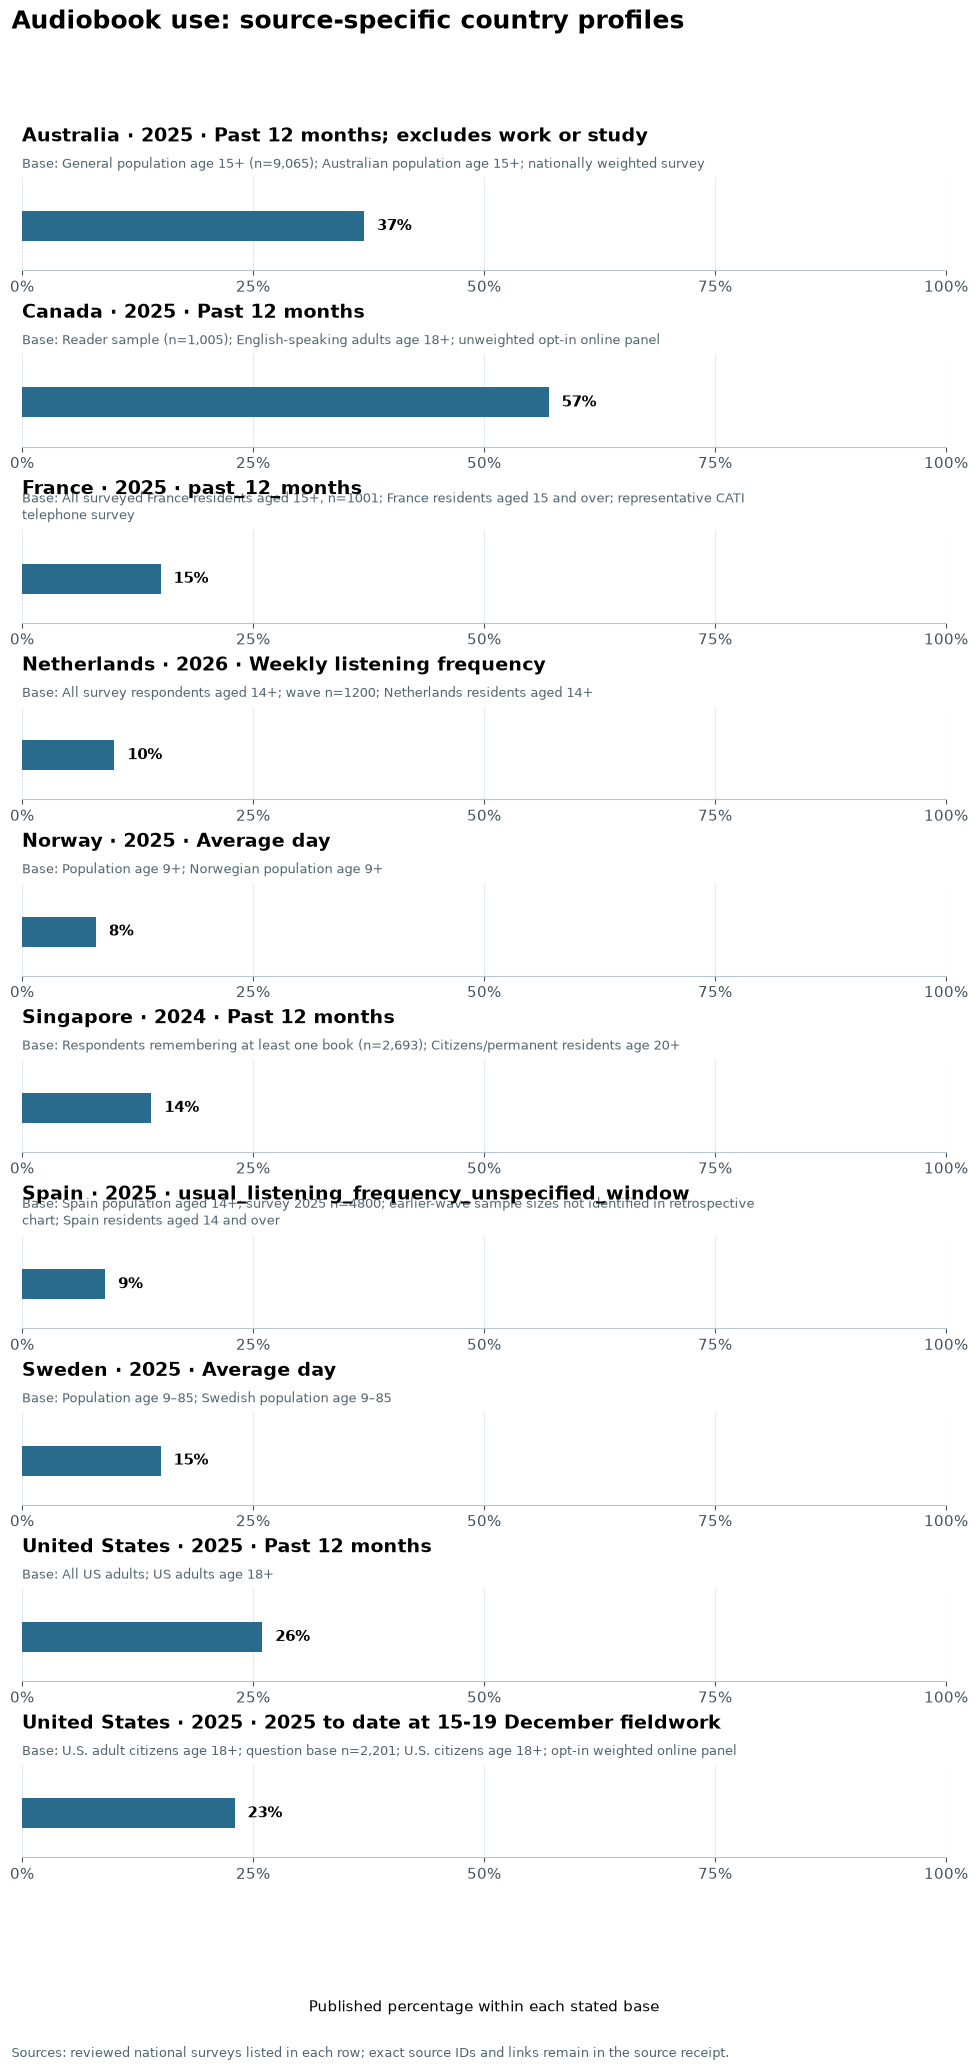

In [5]:
if selected_audio.empty:
    display(Markdown("No selected country has matching audio evidence. Adjust the filters or add a reviewed source."))
else:
    panel_count = len(selected_audio)
    fig, axes = plt.subplots(panel_count, 1, figsize=(10.5, 2.0 * panel_count + 1.0), squeeze=False)
    for ax, row in zip(axes.ravel(), selected_audio.itertuples()):
        ax.barh([0], [row.participation], height=0.34, color=AUDIO_COLOR)
        ax.set_xlim(0, 100)
        ax.set_ylim(-0.5, 0.55)
        ax.set_yticks([])
        ax.set_xticks([0, 25, 50, 75, 100])
        ax.xaxis.set_major_formatter(PercentFormatter(100, decimals=0))
        ax.grid(axis="x", zorder=0)
        ax.set_axisbelow(True)
        ax.set_title(f"{row.country} · {row.year} · {row.period}", loc="left", pad=26)
        ax.text(0, 1.07, textwrap.fill(f"Base: {row.denominator}; {row.population}", 110),
                transform=ax.transAxes, fontsize=9.5, color="#526571", va="bottom")
        ax.text(row.participation + 1.4, 0, f"{row.participation:.0f}%", va="center", fontweight="bold")
        ax.spines["left"].set_visible(False)
    fig.suptitle("Audiobook use: source-specific country profiles", x=0.05, ha="left", fontsize=18, fontweight="bold")
    fig.supxlabel("Published percentage within each stated base", fontsize=11, y=0.025)
    fig.text(0.05, 0.005, "Sources: reviewed national surveys listed in each row; exact source IDs and links remain in the source receipt.",
             fontsize=9, color="#526571")
    fig.subplots_adjust(top=0.90, bottom=0.10, left=0.06, right=0.94, hspace=0.90)
    show_figure(fig, "01_audio_country_profiles")

### 6. Track observed waves from 2022 through the current year

Each panel uses one country, source family, period and population/base definition. Bars show
published observations only. Blank years are missing waves, never zero or an interpolated estimate.
Publication and checking dates belong in the freshness table rather than the observation-year axis.

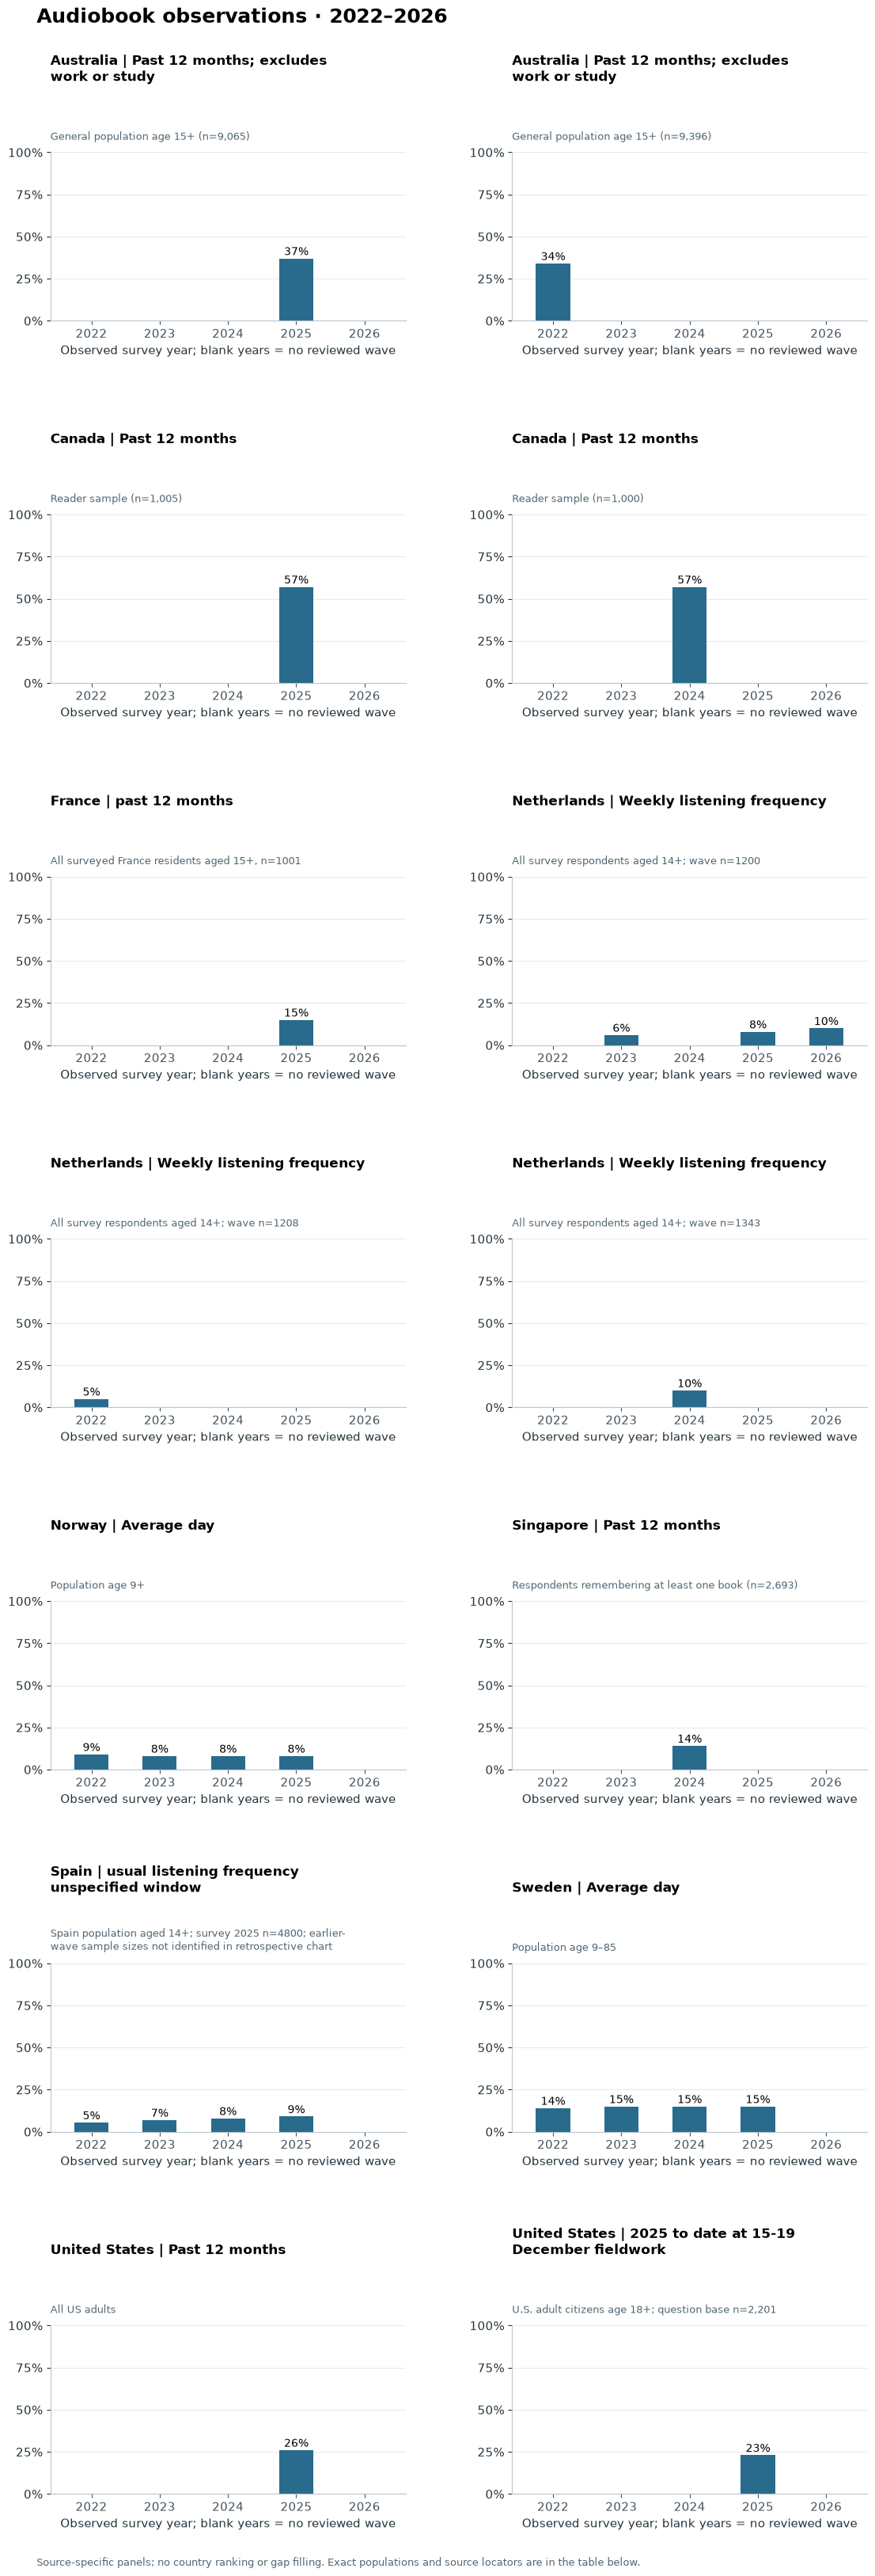

All 14 selected source and survey-base panels are shown separately.

Country,Year,Audio (%),Recall period,Published base,Evidence locator
Australia,2022,34,Past 12 months; excludes work or study,"General population age 15+ (n=9,396)","Printed p.175 (PDF index 176), explicit Of all Australians format percentages; methods pp.16-19 (PDF indices 17-20)"
Australia,2025,37,Past 12 months; excludes work or study,"General population age 15+ (n=9,065)","Printed p.175 (PDF index 176), explicit Of all Australians format percentages; methods pp.16-19 (PDF indices 17-20)"
Canada,2024,57,Past 12 months,"Reader sample (n=1,000)",Format preferences and frequency of reading
Canada,2025,57,Past 12 months,"Reader sample (n=1,005)","Printed p.25 (PDF index 24), readership prose and Reading frequency by format table; methodology p.4; Appendix A Q45"
France,2025,15,past_12_months,"All surveyed France residents aged 15+, n=1001","Printed p.20 (PDF page 20), D4, Focus livre audio, overall donut and legend"
Netherlands,2022,5,Weekly listening frequency,All survey respondents aged 14+; wave n=1208,"Printed p.24 D05 weekly segment, 2022 column; p.5 population; p.72 methods"
Netherlands,2023,6,Weekly listening frequency,All survey respondents aged 14+; wave n=1200,"Printed p.24 D05 weekly segment, 2023 column; p.5 population; p.72 methods"
Netherlands,2024,10,Weekly listening frequency,All survey respondents aged 14+; wave n=1343,"Printed p.24 D05 weekly segment, 2024 column; p.5 population; p.72 methods"
Netherlands,2025,8,Weekly listening frequency,All survey respondents aged 14+; wave n=1200,"Printed p.24 D05 weekly segment, 2025 column; p.5 population; p.72 methods"
Netherlands,2026,10,Weekly listening frequency,All survey respondents aged 14+; wave n=1200,"Printed p.24 D05 weekly segment, 2026 column; p.5 population; p.72 methods"


In [6]:
history = optional_frames.get("audiobook_history")
observed_history = pd.DataFrame()
history_figure_created = False
if history is None:
    display(Markdown("The requested-period listening history file is not present in this snapshot."))
else:
    assert history.participation.dropna().between(0, 100).all()
    history_scope = history[history.country_iso3.isin(CANDIDATE_COUNTRIES) & history.year.between(START_YEAR, END_YEAR)].copy()
    if PERIOD != "All audited periods":
        history_scope = history_scope[history_scope.period.eq(PERIOD)]
    if SOURCE_FAMILY != "All audited profiles":
        history_scope = history_scope[history_scope.comparison_group.eq(SOURCE_FAMILY)]
    signature = ["country", "comparison_group", "period", "population", "denominator", "source_id"]
    assert not history_scope.duplicated(signature + ["year"]).any()
    observed_history = history_scope.dropna(subset=["participation"]).copy()
    groups = list(history_scope.groupby(signature, sort=True, dropna=False))
    visible_groups = groups
    if not visible_groups or observed_history.empty:
        display(Markdown("No published listening wave matches these country, year and source filters."))
    else:
        columns = 2 if len(visible_groups) > 1 else 1
        rows = int(np.ceil(len(visible_groups) / columns))
        fig, axes = plt.subplots(rows, columns, figsize=(11.6, rows * 4.6 + 1.4), squeeze=False)
        for ax, (scope_key, group) in zip(axes.ravel(), visible_groups):
            country, family, period, population, denominator, source_id = scope_key
            wave = group.dropna(subset=["participation"]).sort_values("year")
            ax.bar(wave.year, wave.participation, width=0.5, color=AUDIO_COLOR)
            for value in wave.itertuples():
                ax.text(value.year, value.participation + 2, f"{value.participation:.0f}%", ha="center", fontsize=10)
            ax.set_xlim(START_YEAR - 0.6, END_YEAR + 0.6)
            ax.set_xticks(range(START_YEAR, END_YEAR + 1))
            ax.set_ylim(0, 100)
            ax.set_yticks([0, 25, 50, 75, 100])
            ax.yaxis.set_major_formatter(PercentFormatter(100, decimals=0))
            ax.grid(axis="y")
            ax.set_axisbelow(True)
            history_title = textwrap.fill(f"{country} | {str(period).replace('_', ' ')}", 40)
            ax.set_title(history_title, loc="left", pad=65, fontsize=12)
            ax.text(0, 1.06, textwrap.fill(str(denominator), 55), transform=ax.transAxes,
                    fontsize=9, color="#526571", va="bottom")
            ax.set_xlabel("Observed survey year; blank years = no reviewed wave")
        for unused_ax in axes.ravel()[len(visible_groups):]:
            unused_ax.set_visible(False)
        fig.suptitle(f"Audiobook observations · {START_YEAR}–{END_YEAR}", x=0.065, ha="left", fontsize=18, fontweight="bold")
        fig.text(0.065, 0.018, "Source-specific panels; no country ranking or gap filling. Exact populations and source locators are in the table below.",
                 fontsize=9, color="#526571")
        fig.subplots_adjust(left=0.08, right=0.97, top=1 - 2.5 / fig.get_figheight(),
                            bottom=0.045 if rows > 2 else 0.12, hspace=1.15, wspace=0.30)
        show_figure(fig, "02_audio_observed_history")
        history_figure_created = True
        display(Markdown(f"All {len(groups)} selected source and survey-base panels are shown separately."))
    history_table = history_scope[["country", "year", "participation", "period", "denominator", "evidence_locator"]].sort_values(["country", "year"]).rename(columns={
        "country": "Country", "year": "Year", "participation": "Audio (%)", "period": "Recall period",
        "denominator": "Published base", "evidence_locator": "Evidence locator",
    })
    readable_table(history_table.head(25), {"Year": "{:.0f}", "Audio (%)": "{:.0f}"})
    if len(history_table) > 25:
        display(Markdown(f"Showing 25 of {len(history_table)} selected waves. Full records remain in `data/processed/audiobook_history.csv`."))

### 7. Check historical US adoption as background

Pew's phone-survey observations provide a consistent US history through 2021. Calendar-spaced
points retain the irregular survey years. **2011–2021 lies outside the requested current-period
analysis.** A separate panel shows the 2025 method period; the notebook makes no growth inference across modes.

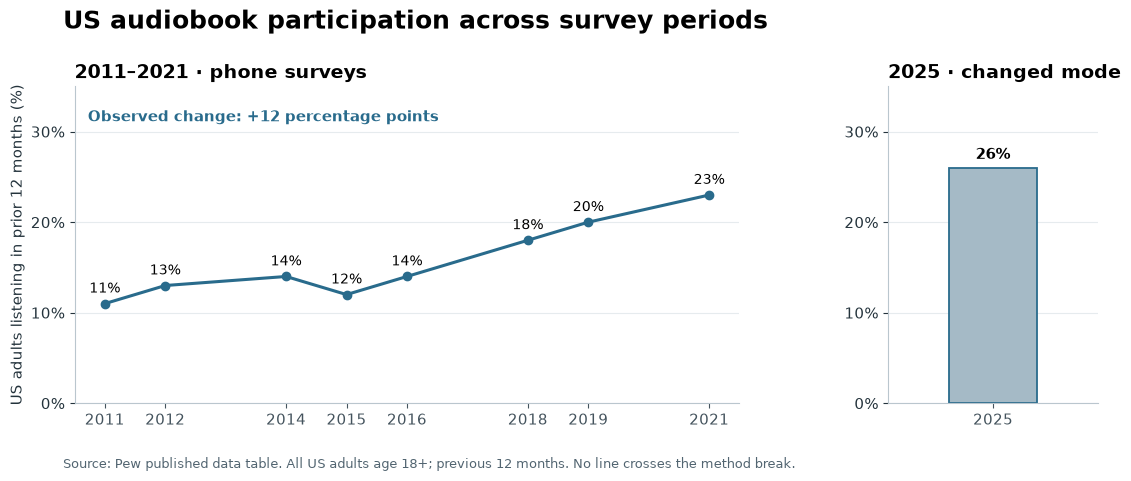

During the phone-survey period, reported participation rose **12 percentage points** from **11%** to **23%**. This is descriptive adoption evidence; the tables do not identify paid listening, Storytel demand, or causal drivers.

In [7]:
phone_start = us_phone.iloc[0]
phone_end = us_phone.iloc[-1]
phone_change = phone_end.participation - phone_start.participation
fig, (ax_history, ax_later) = plt.subplots(1, 2, figsize=(11.5, 4.8), gridspec_kw={"width_ratios": [3.8, 1.2]})
ax_history.plot(us_phone.year, us_phone.participation, color=AUDIO_COLOR, marker="o", linewidth=2.2)
for row in us_phone.itertuples():
    ax_history.annotate(f"{row.participation:.0f}%", (row.year, row.participation), xytext=(0, 8),
                        textcoords="offset points", ha="center", fontsize=10)
ax_history.set_xticks(us_phone.year)
ax_history.set_xlim(2010.5, 2021.5)
ax_history.set_title("2011–2021 · phone surveys", loc="left")
ax_history.set_ylabel("US adults listening in prior 12 months (%)")
ax_history.text(0.02, 0.89, f"Observed change: +{phone_change:.0f} percentage points", transform=ax_history.transAxes,
                fontsize=11, color=AUDIO_COLOR, fontweight="bold")
later_value = us_later.participation.iloc[0]
ax_later.bar([2025], [later_value], width=0.5, color=REFERENCE_COLOR, edgecolor=AUDIO_COLOR, linewidth=1.3)
ax_later.text(2025, later_value + 1, f"{later_value:.0f}%", ha="center", fontweight="bold")
ax_later.set_title("2025 · changed mode", loc="left")
ax_later.set_xticks([2025])
ax_later.set_xlim(2024.4, 2025.6)
for ax in (ax_history, ax_later):
    ax.set_ylim(0, 35)
    ax.set_yticks([0, 10, 20, 30])
    ax.yaxis.set_major_formatter(PercentFormatter(100, decimals=0))
    ax.grid(axis="y")
    ax.set_axisbelow(True)
fig.suptitle("US audiobook participation across survey periods", x=0.07, ha="left", fontsize=18, fontweight="bold")
fig.text(0.07, 0.025, "Source: Pew published data table. All US adults age 18+; previous 12 months. No line crosses the method break.",
         fontsize=9, color="#526571")
fig.subplots_adjust(left=0.08, right=0.97, top=0.82, bottom=0.16, wspace=0.34)
show_figure(fig, "02_us_audio_history")
display(Markdown(f"During the phone-survey period, reported participation rose **{phone_change:.0f} percentage points** "
                 f"from **{phone_start.participation:.0f}%** to **{phone_end.participation:.0f}%**. "
                 "This is descriptive adoption evidence; the tables do not identify paid listening, Storytel demand, or causal drivers."))

### 8. Develop Canadian audiobook fiction hypotheses

The genre charts use the explicitly selected `GENRE_YEAR`, with separate fiction and nonfiction
audiobook reader bases. Bars show that wave's published selections. Source dashes remain
**not published**, rather than zero. Exact within-format genre base sizes and uncertainty are
unavailable; the overall reader sample is not a genre-subgroup denominator.

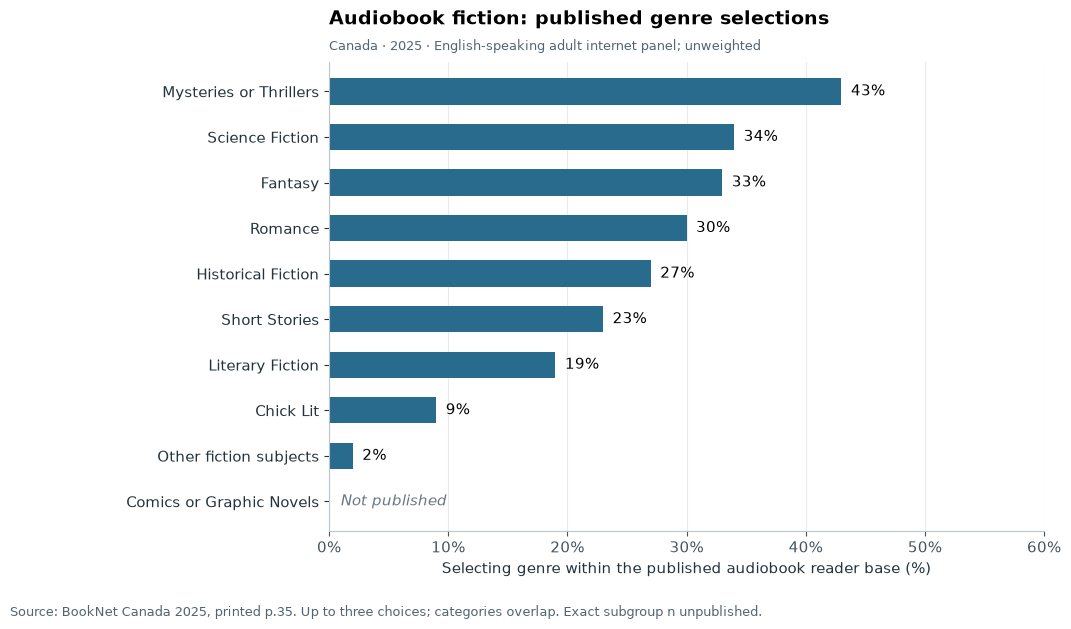

**Canada 2025 source:** [BookNet Canada, printed p.35](https://booknetcanada.ca/wp-content/uploads/2026/06/CanadianLeisureandReading2025.pdf). **Reported genre base:** Fiction readers within format; exact base n unpublished.

**Canada 2025 — Mysteries or Thrillers: 43%** is the leading reported fiction selection. Use it as an English-language catalogue hypothesis to validate against listening, conversion and retention.

In [8]:
assert canada_audio.year.eq(GENRE_YEAR).all(), "Do not pool Canadian genre years."
if GENRE_YEAR == 2024:
    assert canada_audio[(canada_audio.genre_scope.eq("Book fiction genres")) &
                        (canada_audio.genre.eq("Mysteries or Thrillers"))].participation.iloc[0] == 46
    assert canada_audio[(canada_audio.genre_scope.eq("Book non-fiction genres")) &
                        (canada_audio.genre.eq("History"))].participation.iloc[0] == 34
    assert canada_audio[canada_audio.genre.eq("Comics or Graphic Novels")].participation.isna().all()
genre_pages = {2024: {"Book fiction genres": 32, "Book non-fiction genres": 33},
               2025: {"Book fiction genres": 35, "Book non-fiction genres": 37}}
assert GENRE_YEAR in genre_pages, "Review and register PDF genre page locators for this wave."

def audio_genre_chart(scope, title, name):
    table = canada_audio[canada_audio.genre_scope.eq(scope)].copy()
    table = table.sort_values("participation", ascending=False, na_position="last")
    assert table.source_url.nunique() == 1 and table.population.nunique() == 1
    page = genre_pages[GENRE_YEAR][scope]
    observed = table.participation.notna()
    y = np.arange(len(table))
    fig, ax = plt.subplots(figsize=(11, 6.8))
    ax.barh(y[observed], table.loc[observed, "participation"], color=AUDIO_COLOR, height=0.58)
    ax.set_yticks(y, table.genre)
    ax.invert_yaxis()
    ax.set_ylim(len(table) - 0.35, -0.65)
    ax.set_xlim(0, 60)
    ax.set_xticks([0, 10, 20, 30, 40, 50, 60])
    ax.xaxis.set_major_formatter(PercentFormatter(100, decimals=0))
    ax.set_xlabel("Selecting genre within the published audiobook reader base (%)")
    ax.grid(axis="x")
    ax.set_axisbelow(True)
    for position, value in zip(y, table.participation):
        if pd.isna(value):
            ax.text(1, position, "Not published", va="center", color="#687781", fontstyle="italic")
        else:
            ax.text(value + 0.8, position, f"{value:.0f}%", va="center", fontsize=11)
    ax.set_title(title, loc="left", pad=27)
    ax.text(0, 1.025, textwrap.fill(f"Canada · {GENRE_YEAR} · {table.population.iloc[0]}", 100),
            transform=ax.transAxes, fontsize=9.5, color="#526571")
    fig.text(0.02, 0.025,
             f"Source: BookNet Canada {GENRE_YEAR}, printed p.{page}. Up to three choices; categories overlap. Exact subgroup n unpublished.",
             fontsize=9, color="#526571")
    fig.subplots_adjust(left=0.31, right=0.96, top=0.84, bottom=0.15)
    show_figure(fig, name)
    display(Markdown(f"**Canada {GENRE_YEAR} source:** [BookNet Canada, printed p.{page}]({table.source_url.iloc[0]}). "
                     f"**Reported genre base:** {table.denominator.iloc[0]}."))
    return table

fiction_audio = audio_genre_chart("Book fiction genres", "Audiobook fiction: published genre selections",
                                 "03_canada_audio_fiction")
top_fiction = fiction_audio.dropna(subset=["participation"]).iloc[0]
display(Markdown(f"**Canada {GENRE_YEAR} — {top_fiction.genre}: {top_fiction.participation:.0f}%** is the leading reported fiction selection. "
                 "Use it as an English-language catalogue hypothesis to validate against listening, conversion and retention."))

### 9. Develop Canadian nonfiction hypotheses

This is a separate reader base from the fiction chart. A fiction/nonfiction percentage ratio would
not measure their relative market sizes or catalogue value.

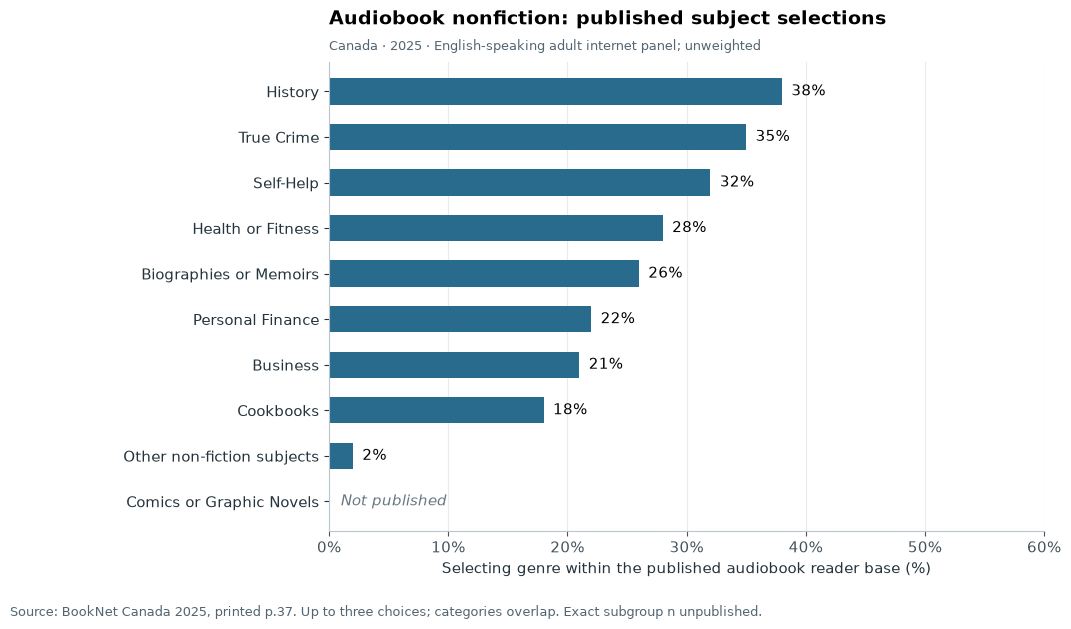

**Canada 2025 source:** [BookNet Canada, printed p.37](https://booknetcanada.ca/wp-content/uploads/2026/06/CanadianLeisureandReading2025.pdf). **Reported genre base:** Non-fiction readers within format; exact base n unpublished.

**Canada 2025 — History: 38%** leads the reported nonfiction choices. Use the selected-wave categories as catalogue hypotheses, subject to local rights and commercial validation.

In [9]:
nonfiction_audio = audio_genre_chart("Book non-fiction genres", "Audiobook nonfiction: published subject selections",
                                    "04_canada_audio_nonfiction")
top_nonfiction = nonfiction_audio.dropna(subset=["participation"]).iloc[0]
display(Markdown(f"**Canada {GENRE_YEAR} — {top_nonfiction.genre}: {top_nonfiction.participation:.0f}%** leads the reported nonfiction choices. "
                 "Use the selected-wave categories as catalogue hypotheses, subject to local rights and commercial validation."))

### 10. Compare the same 2026 audiobook genre question

The Storytel-commissioned report asks the same genre question across Sweden, Norway, Finland,
Poland and Bulgaria. The selected category is an exact original label. Each percentage describes
the published listener base, not all adults or Storytel customers. Top-five publication means an
absent category is **unreported**, even if it appears in another country.

These two 2026 reference figures use the candidate-country list and requested-year range.
Adoption/reach period and source-family filters above do not change their listener-preference definition.

**Fieldwork:** April 2026. **Published:** 2026-06-24. **Overall sample:** 5,077; this is not the listener denominator. **Question:** Which genres do you listen to most often?

**Available original genre labels:** Biography/Memoir; Classics; Crime/Thriller; Fantasy/Sci-fi; Feel-good; Fiction; Non-fiction; Romance; Self-imp./Pers. dev.; True Crime.

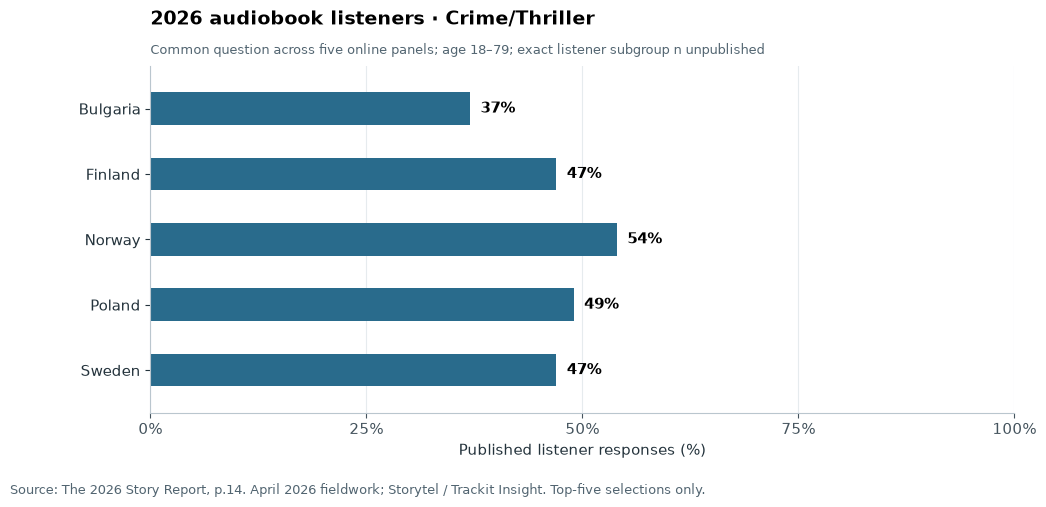

Country,Selected genre (%)
Bulgaria,37
Finland,47
Norway,54
Poland,49
Sweden,47


This is a common-question preference comparison. It does not establish listener-market size, statistical significance, country investment priority or catalogue ROI.

In [10]:
storytel = optional_frames.get("storytel_audio_2026")
storytel_genre_figure_created = False
storytel_moment_figure_created = False
storytel_scope = pd.DataFrame()
research_metadata_path = ROOT / "data/curated/storytel_research_metadata.json"
research_metadata = None
if storytel is None:
    display(Markdown("The validated 2026 common-question source is absent from this snapshot."))
else:
    assert storytel.participation.between(0, 100).all()
    assert set(storytel.record_type) == {"genre", "moment"}
    assert storytel.format_label.eq("Audiobook").all()
    assert not storytel.duplicated(["country_iso3", "year", "record_type", "item"]).any()
    assert storytel.groupby(["country_iso3", "record_type"]).size().eq(5).all()
    assert storytel.sample_size.isna().all(), "Listener-subgroup n is unpublished."
    if research_metadata_path.is_file():
        research_metadata = json.loads(research_metadata_path.read_text())
        assert research_metadata["source_url"] in set(storytel.source_url)
        assert len(research_metadata["sha256"]) == 64
        display(Markdown(
            f"**Fieldwork:** {research_metadata['fieldwork']}. **Published:** {research_metadata['publication_date']}. "
            f"**Overall sample:** {research_metadata['total_sample']:,}; this is not the listener denominator. "
            f"**Question:** {research_metadata['genre_question']}"
        ))
    genre_labels = sorted(storytel[storytel.record_type.eq("genre")].item.unique())
    assert SELECTED_2026_GENRE in genre_labels, "Use an original published genre label."
    display(Markdown("**Available original genre labels:** " + "; ".join(genre_labels) + "."))
    storytel_scope = storytel[storytel.country_iso3.isin(CANDIDATE_COUNTRIES) & storytel.year.between(START_YEAR, END_YEAR)].copy()
    comparison_countries = sorted(storytel_scope.country.unique())
    if not comparison_countries:
        display(Markdown("No candidate country has a 2026 listener-preference record in the selected year range."))
    else:
        selected_genre_rows = storytel_scope[storytel_scope.record_type.eq("genre") & storytel_scope.item.eq(SELECTED_2026_GENRE)]
        genre_values = selected_genre_rows.set_index("country").participation.reindex(comparison_countries)
        y = np.arange(len(genre_values))
        published = genre_values.notna().to_numpy()
        fig, ax = plt.subplots(figsize=(10.8, 5.5))
        ax.barh(y[published], genre_values.to_numpy()[published], color=AUDIO_COLOR, height=0.5)
        ax.set_yticks(y, comparison_countries)
        ax.set_ylim(len(genre_values) - 0.35, -0.65)
        ax.set_xlim(0, 100)
        ax.set_xticks([0, 25, 50, 75, 100])
        ax.xaxis.set_major_formatter(PercentFormatter(100, decimals=0))
        ax.grid(axis="x")
        ax.set_axisbelow(True)
        for position, value in zip(y, genre_values):
            if pd.isna(value):
                ax.text(1, position, "Unreported in top five", va="center", color="#687781", fontstyle="italic")
            else:
                ax.text(value + 1.2, position, f"{value:.0f}%", va="center", fontweight="bold")
        ax.set_title(f"2026 audiobook listeners · {SELECTED_2026_GENRE}", loc="left", pad=30)
        ax.text(0, 1.035, "Common question across five online panels; age 18–79; exact listener subgroup n unpublished",
                transform=ax.transAxes, fontsize=9.5, color="#526571")
        ax.set_xlabel("Published listener responses (%)")
        fig.text(0.02, 0.022,
                 "Source: The 2026 Story Report, p.14. April 2026 fieldwork; Storytel / Trackit Insight. Top-five selections only.",
                 fontsize=9, color="#526571")
        fig.subplots_adjust(left=0.15, right=0.95, top=0.80, bottom=0.17)
        show_figure(fig, "05_storytel_2026_selected_genre")
        storytel_genre_figure_created = True
        genre_comparison_table = genre_values.rename("Selected genre (%)").reset_index().rename(columns={"country": "Country"})
        readable_table(genre_comparison_table, {"Selected genre (%)": "{:.0f}"})
        display(Markdown("This is a common-question preference comparison. It does not establish listener-market size, "
                         "statistical significance, country investment priority or catalogue ROI."))

### 11. Explore listening moments for existing-market growth

The heatmap retains the union of published listening occasions. **Unreported** cells indicate a
category outside that country's published top five. They cannot be interpreted as zero usage.
Occasions overlap, and no percentages are added together.

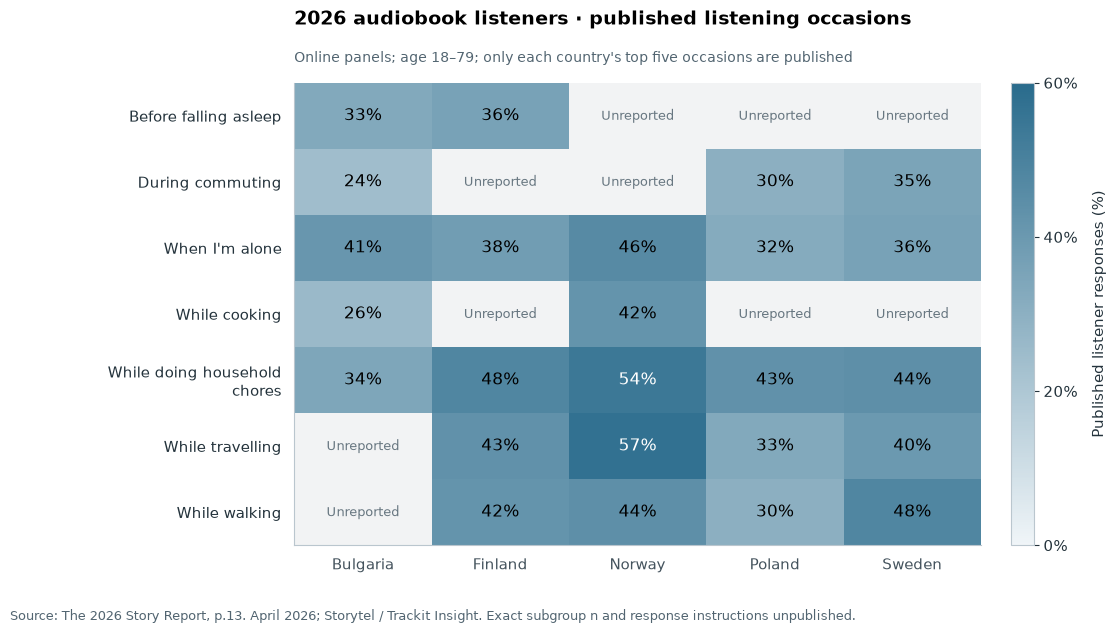

Use observed occasions to develop audience and messaging hypotheses in existing markets. Validate them with local conversion, listening and retention evidence before allocating incremental spend.

In [11]:
if not storytel_scope.empty:
    moments = storytel_scope[storytel_scope.record_type.eq("moment")]
    moment_matrix = moments.pivot(index="item", columns="country", values="participation")
    moment_matrix = moment_matrix.reindex(index=sorted(moment_matrix.index), columns=sorted(moment_matrix.columns))
    matrix = moment_matrix.to_numpy(dtype=float)
    cmap = matplotlib.colors.LinearSegmentedColormap.from_list("audio_moments", ["#f0f5f8", AUDIO_COLOR])
    cmap.set_bad("#f2f3f4")
    fig, ax = plt.subplots(figsize=(11.6, 6.8))
    image = ax.imshow(np.ma.masked_invalid(matrix), cmap=cmap, vmin=0, vmax=60, aspect="auto")
    ax.set_xticks(np.arange(len(moment_matrix.columns)), moment_matrix.columns)
    ax.set_yticks(np.arange(len(moment_matrix.index)), [textwrap.fill(label, 26) for label in moment_matrix.index])
    ax.tick_params(axis="both", length=0, pad=9)
    for row in range(matrix.shape[0]):
        for column in range(matrix.shape[1]):
            value = matrix[row, column]
            if np.isnan(value):
                ax.text(column, row, "Unreported", ha="center", va="center", fontsize=9, color="#687781")
            else:
                rgb = np.array(cmap(image.norm(value))[:3])
                linear_rgb = np.where(rgb <= 0.04045, rgb / 12.92, ((rgb + 0.055) / 1.055) ** 2.4)
                luminance = float(linear_rgb @ np.array([0.2126, 0.7152, 0.0722]))
                text_color = "white" if 1.05 / (luminance + 0.05) >= (luminance + 0.05) / 0.05 else "black"
                ax.text(column, row, f"{value:.0f}%", ha="center", va="center", fontsize=12,
                        color=text_color)
    ax.set_title("2026 audiobook listeners · published listening occasions", loc="left", pad=42)
    ax.text(0, 1.045, "Online panels; age 18–79; only each country's top five occasions are published",
            transform=ax.transAxes, fontsize=10, color="#526571")
    colorbar = fig.colorbar(image, ax=ax, fraction=0.035, pad=0.04)
    colorbar.set_label("Published listener responses (%)", labelpad=10)
    colorbar.set_ticks([0, 20, 40, 60], labels=["0%", "20%", "40%", "60%"])
    fig.text(0.025, 0.02,
             "Source: The 2026 Story Report, p.13. April 2026; Storytel / Trackit Insight. Exact subgroup n and response instructions unpublished.",
             fontsize=9, color="#526571")
    fig.subplots_adjust(left=0.27, right=0.91, top=0.81, bottom=0.13)
    show_figure(fig, "06_storytel_2026_listening_moments")
    storytel_moment_figure_created = True
    display(Markdown("Use observed occasions to develop audience and messaging hypotheses in existing markets. "
                     "Validate them with local conversion, listening and retention evidence before allocating incremental spend."))
else:
    display(Markdown("No selected 2026 listening-occasion observations are available."))

## Expanded survey coverage and audiobook genres

This refresh adds national reading and audiobook evidence from several independent survey
families. The inventory below shows which observation years are available without pooling
percentages. The Netherlands weekly listening survey includes a reviewed 2026 observation.
Audible's four-country genre survey was conducted in 2025. A release published during 2026
can still describe an earlier observation year. Read each row's population, question and recall period.

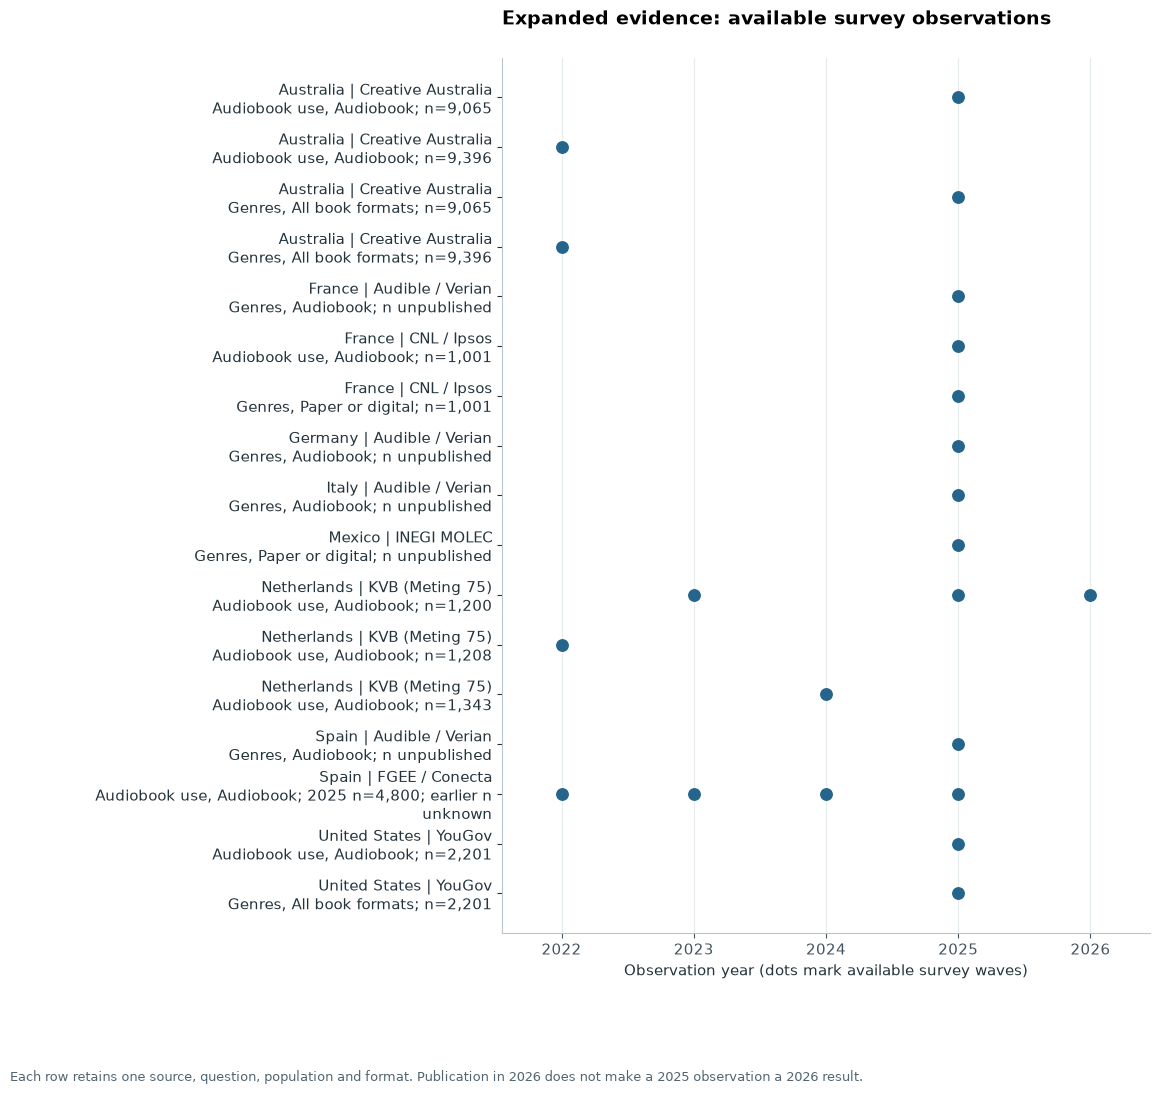

Country,Source,Evidence,Format,Question,Survey base,Recall period,Observation years
Australia,creative_au,Audiobook use,Audiobook,Australia annual population reach,"General population age 15+ (n=9,065)",Past 12 months; excludes work or study,2025
Australia,creative_au,Audiobook use,Audiobook,Australia annual population reach,"General population age 15+ (n=9,396)",Past 12 months; excludes work or study,2022
Australia,creative_au,Genres,All book formats,Book forms read for pleasure,"General population age 15+ (n=9,065)",Past 12 months; excludes work or study,2025
Australia,creative_au,Genres,All book formats,Book forms read for pleasure,"General population age 15+ (n=9,396)",Past 12 months; excludes work or study,2022
France,audible_compass_2025,Genres,Audiobook,Audiobook genres among past-year listeners,Respondents who listened to an audiobook in the past 12 months; listener subset n not published,past_12_months_listener_base,2025
France,cnl_fr,Audiobook use,Audiobook,France 15+ annual audiobook listening,"All surveyed France residents aged 15+, n=1001",past_12_months,2025
France,cnl_fr,Genres,Paper or digital,"Book genres, paper or digital","All surveyed France residents aged 15+, n=1001, including nonreaders",past_12_months,2025
Germany,audible_compass_2025,Genres,Audiobook,Audiobook genres among past-year listeners,Respondents who listened to an audiobook in the past 12 months; listener subset n not published,past_12_months_listener_base,2025
Italy,audible_compass_2025,Genres,Audiobook,Audiobook genres among past-year listeners,Respondents who listened to an audiobook in the past 12 months; listener subset n not published,past_12_months_listener_base,2025
Mexico,inegi_mx,Genres,Paper or digital,"Book types read, paper or digital",Literate residents aged 12+ who read a book in the past 12 months; exact reader subgroup n unpublished,Past 12 months,2025


**8 countries** and **7 source families** appear in this expanded inventory. The counts describe coverage only. They are not audience totals or a country ranking.

In [12]:
REFRESH_START_YEAR = 2022
REFRESH_END_YEAR = pd.Timestamp.today().year
SELECTED_GENRE_COUNTRY = "Germany"
SELECTED_GENRE_SOURCE = "audible_compass_2025"
SELECTED_GENRE_QUESTION = "Audiobook genres among past-year listeners"
SELECTED_GENRE_FORMAT = "Audiobook"
SELECTED_GENRE_YEAR = 2025
assert REFRESH_START_YEAR <= SELECTED_GENRE_YEAR <= REFRESH_END_YEAR
refreshed_genres = genre_observations.copy()
refreshed_audio = optional_frames["audiobook_history"].copy()

coverage_parts = []
for evidence_kind, evidence_frame in [("Audiobook use", refreshed_audio), ("Genres", refreshed_genres)]:
    frame = evidence_frame.copy()
    frame = frame[frame.year.between(REFRESH_START_YEAR, REFRESH_END_YEAR)]
    frame = frame[~frame.source_id.isin({"booknet_ca", "nlb_sg", "ssb_no", "nordicom_se", "pew_us"})]
    if "format_label" not in frame:
        frame["format_label"] = "Audiobook"
    frame["Evidence"] = evidence_kind
    frame["Question"] = frame["genre_scope"] if evidence_kind == "Genres" else frame["comparison_group"]
    coverage_parts.append(frame[["country", "source_id", "year", "format_label", "Evidence", "Question", "denominator", "period"]])
refreshed_coverage = pd.concat(coverage_parts, ignore_index=True).drop_duplicates()
assert not refreshed_coverage.empty, "Build the reviewed data refresh before this notebook."
scope_columns = ["country", "source_id", "Evidence", "format_label", "Question", "denominator", "period"]
coverage_inventory = (refreshed_coverage.groupby(scope_columns, dropna=False, sort=True)["year"]
                      .agg(lambda values: tuple(sorted(set(int(value) for value in values)))).reset_index())
fig, ax = plt.subplots(figsize=(12, max(5.2, 0.59 * len(coverage_inventory) + 1.8)))
import re
coverage_source_names = {
    "creative_au": "Creative Australia",
    "cnl_fr": "CNL / Ipsos",
    "audible_compass_2025": "Audible / Verian",
    "inegi_mx": "INEGI MOLEC",
    "kvb_nl_m75": "KVB (Meting 75)",
    "fgee_es": "FGEE / Conecta",
    "yougov_us_2025_books": "YouGov",
}
coverage_labels = []
for position, row in enumerate(coverage_inventory.itertuples(index=False)):
    ax.scatter(row.year, [position] * len(row.year), s=68, marker="o", color="#25658c", zorder=3)
    source_name = coverage_source_names.get(row.source_id, str(row.source_id).replace("_", " "))
    base_match = re.search(r"\bn\s*=\s*([\d,]+)", str(row.denominator))
    base_note = f"n={int(base_match.group(1).replace(',', '')):,}" if base_match else "n unpublished"
    if row.source_id == "fgee_es":
        base_note = "2025 n=4,800; earlier n unknown"
    coverage_labels.append(f"{row.country} | {source_name}\n" +
                           textwrap.fill(f"{row.Evidence}, {row.format_label}; {base_note}", 52))
ax.set_yticks(range(len(coverage_inventory)), coverage_labels)
ax.invert_yaxis()
ax.set_xticks(range(REFRESH_START_YEAR, REFRESH_END_YEAR + 1))
ax.set_xlim(REFRESH_START_YEAR - 0.45, REFRESH_END_YEAR + 0.45)
ax.set_title("Expanded evidence: available survey observations", loc="left", pad=24)
ax.set_xlabel("Observation year (dots mark available survey waves)")
ax.grid(axis="x")
ax.set_axisbelow(True)
fig.text(0.02, 0.015, "Each row retains one source, question, population and format. Publication in 2026 does not make a 2025 observation a 2026 result.",
         fontsize=9, color="#526571")
fig.subplots_adjust(left=0.43, right=0.97, top=0.88, bottom=0.14)
show_figure(fig, "09_expanded_survey_coverage")
coverage_table = coverage_inventory.copy()
coverage_table["year"] = coverage_table.year.map(lambda years: ", ".join(str(year) for year in years))
coverage_table = coverage_table.rename(columns={"country": "Country", "source_id": "Source", "year": "Observation years",
                                                "format_label": "Format", "denominator": "Survey base", "period": "Recall period"})
readable_table(coverage_table.head(18))
display(Markdown(f"**{refreshed_coverage.country.nunique()} countries** and **{refreshed_coverage.source_id.nunique()} source families** appear in this expanded inventory. "
                 "The counts describe coverage only. They are not audience totals or a country ranking."))
if len(coverage_table) > 18:
    display(Markdown(f"Showing 18 of {len(coverage_table)} source scopes. Full rows and exact source links remain in the reviewed CSV files."))

### Select one country, source and genre question

The parameters above select a single reviewed country, survey source, question, format and
observation year. The default uses Germany's 2025 audiobook listener study commissioned by
Audible and conducted by Verian. It complements the Canadian format questions and the separate
2026 Story Report. The full country survey had 1,000 online respondents aged 18 to 65;
the exact audiobook listener subset size is unpublished. No broader podcast audience is used here.

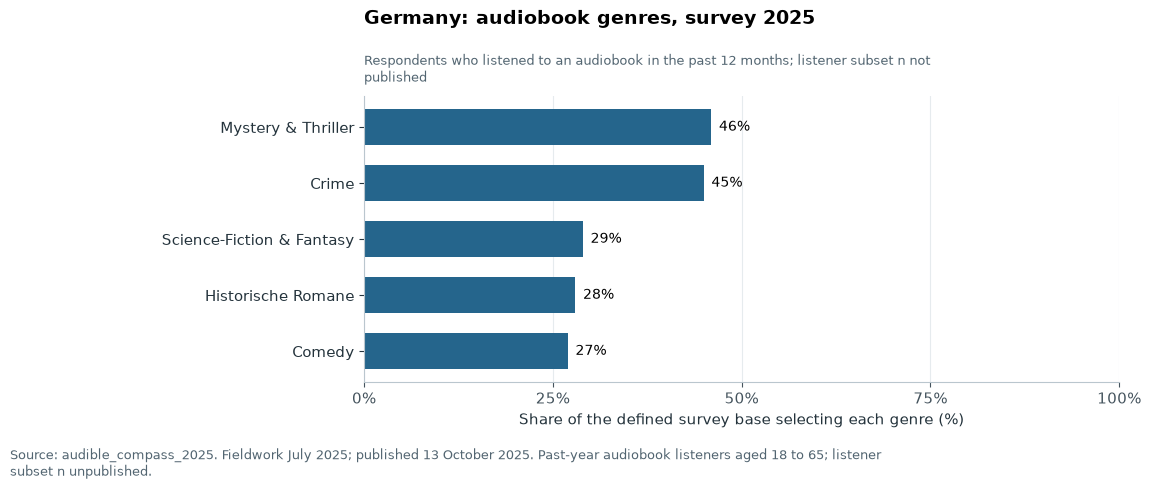

**Question:** Audiobook genres among past-year listeners. **Recall:** past_12_months_listener_base. **Population:** Online respondents aged 18 to 65; country survey n=1000; commissioned by Audible and conducted by Verian. [Original source](https://buchcontact.de/wp-content/uploads/2025/09/Audible-Hoerkompass-2025_Infografiken.pdf). **Locator:** Infographics PDF p.2, Die beliebtesten Hörbuch-Genres in Deutschland, Frankreich, Italien und Spanien, Germany panel; respondent base and multiple-answer footnote.

Only five published categories per country. Multiple answers allowed, not market shares. Fieldwork July 2025, publication 13 October 2025. Original category labels retained from German-language infographic. This is audiobook listener genre choice, not national audiobook participation. Do not reuse the separate combined audiobook/audio-drama/podcast audience headline.

Categories may overlap. A reported top five omits other choices; absence is not zero. These percentages describe this survey base and do not establish national listening participation or catalogue market shares.

In [13]:
selected_genre_rows = refreshed_genres[
    refreshed_genres.country.eq(SELECTED_GENRE_COUNTRY) &
    refreshed_genres.source_id.eq(SELECTED_GENRE_SOURCE) &
    refreshed_genres.genre_scope.eq(SELECTED_GENRE_QUESTION) &
    refreshed_genres.format_label.eq(SELECTED_GENRE_FORMAT) &
    refreshed_genres.year.eq(SELECTED_GENRE_YEAR)
].copy()
assert not selected_genre_rows.empty, "Choose a country, source, question, format and year present in genre_history.csv."
assert selected_genre_rows[["population", "denominator", "period"]].drop_duplicates().shape[0] == 1
assert not selected_genre_rows.genre.duplicated().any()
selected_genre_rows = selected_genre_rows.sort_values(["participation", "genre"], na_position="first")
genre_definition = selected_genre_rows.iloc[0]
fig, ax = plt.subplots(figsize=(11.8, max(5.2, 0.46 * len(selected_genre_rows) + 2.2)))
for position, row in enumerate(selected_genre_rows.itertuples()):
    if pd.isna(row.participation):
        ax.text(1, position, "Not published", va="center", color="#687781", fontstyle="italic")
    else:
        ax.barh(position, row.participation, color="#25658c", height=0.64)
        ax.text(row.participation + 1, position, f"{row.participation:g}%", va="center", fontsize=10)
ax.set_yticks(range(len(selected_genre_rows)), [textwrap.fill(str(label), 32) for label in selected_genre_rows.genre])
ax.set_xlim(0, 100)
ax.set_xticks([0, 25, 50, 75, 100], ["0%", "25%", "50%", "75%", "100%"])
ax.set_xlabel("Share of the defined survey base selecting each genre (%)")
ax.set_title(f"{SELECTED_GENRE_COUNTRY}: {SELECTED_GENRE_FORMAT.lower()} genres, survey {SELECTED_GENRE_YEAR}", loc="left", pad=52)
ax.text(0, 1.035, textwrap.fill(str(genre_definition.denominator), 86), transform=ax.transAxes,
        fontsize=9.5, color="#526571", va="bottom")
ax.grid(axis="x")
ax.set_axisbelow(True)
publication_notes = {
    "audible_compass_2025": "Fieldwork July 2025; published 13 October 2025. Past-year audiobook listeners aged 18 to 65; listener subset n unpublished.",
    "cnl_fr": "Fieldwork 21 January to 4 February 2025; published 8 April 2025. France age 15+, all respondents n=1,001.",
}
selected_date_note = publication_notes.get(SELECTED_GENRE_SOURCE, "Survey year is shown above. Exact fieldwork and publication dates are preserved in the source notes below.")
fig.text(0.02, 0.02, textwrap.fill(f"Source: {SELECTED_GENRE_SOURCE}. {selected_date_note}", 136), fontsize=9, color="#526571")
fig.subplots_adjust(left=0.32, right=0.96, top=0.75, bottom=0.20)
show_figure(fig, "10_selected_source_genres")
display(Markdown(f"**Question:** {SELECTED_GENRE_QUESTION}. **Recall:** {genre_definition.period}. "
                 f"**Population:** {genre_definition.population}. "
                 f"[Original source]({genre_definition.source_url}). **Locator:** {genre_definition.evidence_locator}."))
display(Markdown(str(genre_definition.notes)))
display(Markdown("Categories may overlap. A reported top five omits other choices; absence is not zero. "
                 "These percentages describe this survey base and do not establish national listening participation or catalogue market shares."))

### 12. Keep the country decision auditable

The source inventory marks the evidence available here. **Available** describes a cached survey
observation; it does not rate commercial attractiveness. Missing annual adoption, genre evidence,
or current Storytel status remains a research task.

If the project's market-evidence CSV is present, the next cell displays its candidate-country
records as a bounded research table. It does not combine fields into a score.

In [14]:
countries = pd.concat([format_observations[["country_iso3", "country"]],
                       genre_observations[["country_iso3", "country"]],
                       audio_profiles[["country_iso3", "country"]]], ignore_index=True).drop_duplicates().sort_values("country")
if storytel is not None:
    countries = pd.concat([countries, storytel[["country_iso3", "country"]]], ignore_index=True).drop_duplicates().sort_values("country")
evidence_rows = []
for row in countries.itertuples():
    profiles = audio_profiles[audio_profiles.country_iso3.eq(row.country_iso3)].sort_values("year", ascending=False)
    profile = profiles.iloc[0] if not profiles.empty else None
    selected_genres = genre_observations[genre_observations.country_iso3.eq(row.country_iso3) &
                                        genre_observations.format_label.eq("Audiobook") &
                                        genre_observations.year.between(START_YEAR, END_YEAR)]
    audio_genre_count = selected_genres.participation.notna().sum()
    common_genre_count = 0 if storytel is None else len(storytel[storytel.country_iso3.eq(row.country_iso3) & storytel.record_type.eq("genre")])
    genre_years = ", ".join(str(int(year)) for year in sorted(selected_genres.year.unique()))
    genre_coverage = (f"{audio_genre_count} reviewed category records; {selected_genres.source_id.nunique()} source(s); years {genre_years}"
                      if audio_genre_count else "Unavailable here")
    if common_genre_count:
        genre_coverage += f"; {common_genre_count} published 2026 Story Report selections"
    evidence_rows.append({
        "Country": row.country,
        "Audio observation": f"{profile.participation:.0f}% · {profile.period} · {profile.year}" if profile is not None else "Adoption/reach unavailable here",
        "Published base": profile.denominator if profile is not None else "No reviewed population listening measure; inspect genre source base separately",
        "Audio genres": genre_coverage,
        "Consistent audio history": ("2011–2021 phone surveys" if row.country_iso3 == "USA" else
                                     "See 2022+ source-scope panels" if history is not None and row.country_iso3 in set(history.country_iso3) else "Unavailable here"),
    })
evidence_table = pd.DataFrame(evidence_rows)
readable_table(evidence_table)

market_path = ROOT / "data/processed/audio_market_evidence.csv"
market_evidence = None
if market_path.is_file():
    market_evidence = optional_frames["audio_market_evidence"].copy()
    iso_column = next((column for column in ["country_iso3", "iso3"] if column in market_evidence.columns), None)
    if iso_column:
        market_evidence = market_evidence[market_evidence[iso_column].isin(CANDIDATE_COUNTRIES)]
    if DECISION_TRACK != "Both" and "decision_route" in market_evidence.columns:
        route_keyword = "entry" if DECISION_TRACK == "New entry" else "growth"
        market_evidence = market_evidence[market_evidence.decision_route.str.contains(route_keyword, case=False, na=False)]

    identity = [column for column in [iso_column, "country"] if column and column in market_evidence.columns]
    columns = [column for column in market_evidence.columns if column not in identity]
    display(Markdown("**Project market-evidence table** — source-specific research records; no composite score."))
    for start in range(0, len(columns), 4):
        readable_table(market_evidence[identity + columns[start:start + 4]].head(20))
    if len(market_evidence) > 20:
        display(Markdown(f"Showing the first 20 of {len(market_evidence)} selected evidence records in each column group."))
else:
    display(Markdown("The optional market-evidence file is absent. The audited listening inventory above remains available."))

Country,Audio observation,Published base,Audio genres,Consistent audio history
Australia,37% · Past 12 months; excludes work or study · 2025,"General population age 15+ (n=9,065)",Unavailable here,See 2022+ source-scope panels
Bulgaria,Adoption/reach unavailable here,No reviewed population listening measure; inspect genre source base separately,Unavailable here; 5 published 2026 Story Report selections,Unavailable here
Canada,57% · Past 12 months · 2025,"Reader sample (n=1,005)","36 reviewed category records; 1 source(s); years 2024, 2025",See 2022+ source-scope panels
Finland,Adoption/reach unavailable here,No reviewed population listening measure; inspect genre source base separately,Unavailable here; 5 published 2026 Story Report selections,Unavailable here
France,15% · past_12_months · 2025,"All surveyed France residents aged 15+, n=1001",5 reviewed category records; 1 source(s); years 2025,See 2022+ source-scope panels
Germany,Adoption/reach unavailable here,No reviewed population listening measure; inspect genre source base separately,5 reviewed category records; 1 source(s); years 2025,Unavailable here
Italy,Adoption/reach unavailable here,No reviewed population listening measure; inspect genre source base separately,5 reviewed category records; 1 source(s); years 2025,Unavailable here
Mexico,Adoption/reach unavailable here,No reviewed population listening measure; inspect genre source base separately,Unavailable here,Unavailable here
Netherlands,10% · Weekly listening frequency · 2026,All survey respondents aged 14+; wave n=1200,Unavailable here,See 2022+ source-scope panels
Norway,8% · Average day · 2025,Population age 9+,Unavailable here; 5 published 2026 Story Report selections,See 2022+ source-scope panels


**Project market-evidence table** — source-specific research records; no composite score.

country_iso3,country,decision_route,brand_presence,group_presence,footprint_note
SWE,Sweden,new_entry,Existing Storytel storefront,Existing Group market,Existing Nordic business; included in the Nordics reporting segment from Q1 2026.
SWE,Sweden,existing_growth,Existing Storytel storefront,Existing Group market,Existing Nordic business; included in the Nordics reporting segment from Q1 2026.
NOR,Norway,new_entry,Existing Storytel storefront,Existing Group market,Existing Nordic business and joint venture; included in the Nordics reporting segment from Q1 2026.
NOR,Norway,existing_growth,Existing Storytel storefront,Existing Group market,Existing Nordic business and joint venture; included in the Nordics reporting segment from Q1 2026.
FIN,Finland,new_entry,Existing Storytel storefront,Existing Group market,Existing Nordic business; included in the Nordics reporting segment from Q1 2026.
FIN,Finland,existing_growth,Existing Storytel storefront,Existing Group market,Existing Nordic business; included in the Nordics reporting segment from Q1 2026.
POL,Poland,new_entry,Existing Storytel storefront,Existing Group market,Existing core growth market; included in the Europe reporting segment from Q1 2026.
POL,Poland,existing_growth,Existing Storytel storefront,Existing Group market,Existing core growth market; included in the Europe reporting segment from Q1 2026.
BGR,Bulgaria,new_entry,Existing Storytel storefront,Existing Group market,Existing core growth market; included in the Europe reporting segment from Q1 2026.
BGR,Bulgaria,existing_growth,Existing Storytel storefront,Existing Group market,Existing core growth market; included in the Europe reporting segment from Q1 2026.


country_iso3,country,decision_gap,source_url,reviewed_at
SWE,Sweden,Existing Group market: exclude from new Group-country launches. A separate brand or proposition change needs explicit scope.,https://www.storytel.com/store-select,2026-10-08
SWE,Sweden,"Need country-level active/paying listener penetration, retention, acquisition cost, contribution margin and catalogue rights to prioritize incremental investment.",https://www.storytel.com/store-select,2026-10-08
NOR,Norway,Existing Group market: exclude from new Group-country launches. A separate brand or proposition change needs explicit scope.,https://www.storytel.com/store-select,2026-10-08
NOR,Norway,"Need country-level active/paying listener penetration, retention, acquisition cost, contribution margin and catalogue rights to prioritize incremental investment.",https://www.storytel.com/store-select,2026-10-08
FIN,Finland,Existing Group market: exclude from new Group-country launches. A separate brand or proposition change needs explicit scope.,https://www.storytel.com/store-select,2026-10-08
FIN,Finland,"Need country-level active/paying listener penetration, retention, acquisition cost, contribution margin and catalogue rights to prioritize incremental investment.",https://www.storytel.com/store-select,2026-10-08
POL,Poland,Existing Group market: exclude from new Group-country launches. A separate brand or proposition change needs explicit scope.,https://www.storytel.com/store-select,2026-10-08
POL,Poland,"Need country-level active/paying listener penetration, retention, acquisition cost, contribution margin and catalogue rights to prioritize incremental investment.",https://www.storytel.com/store-select,2026-10-08
BGR,Bulgaria,Existing Group market: exclude from new Group-country launches. A separate brand or proposition change needs explicit scope.,https://www.storytel.com/store-select,2026-10-08
BGR,Bulgaria,"Need country-level active/paying listener penetration, retention, acquisition cost, contribution margin and catalogue rights to prioritize incremental investment.",https://www.storytel.com/store-select,2026-10-08


### 13. Check refresh status and evidence age

Observation year, publication date, source-check date and last successful data refresh answer
different questions. An automated check can succeed without a new survey wave. A failed retrieval
does not erase the last validated cached observation or make it current.

In [15]:
freshness = optional_frames.get("data_freshness")
if freshness is None:
    display(Markdown("No structured refresh-status file is present. Review the snapshot build timestamp and source receipt above."))
else:

    identity_columns = [column for column in ["source_id", "country", "source"] if column in freshness.columns]
    other_columns = [column for column in freshness.columns if column not in identity_columns]
    for start in range(0, len(other_columns), 4):
        readable_table(freshness[identity_columns + other_columns[start:start + 4]].head(20))
    if len(freshness) > 20:
        display(Markdown(f"Showing 20 of {len(freshness)} source-status rows. Full records remain in `data/processed/data_freshness.csv`."))

source_id,source_name,latest_observation_year,last_checked_at,status
eurostat,EU-SILC book participation / ilc_scp27,2022.000000,2026-10-26T11:37:31.090504+00:00,API refreshed and validated
pew_us,Book formats 2011–2025,2025.000000,2026-10-26T11:37:31.090650+00:00,Current evidence reviewed; validated observations retained
cnl_fr,Les Français et la lecture 2025,2025.000000,2026-10-26T11:37:31.090735+00:00,Changed source; extraction review needed
nordicom_se,Mediebarometern 2022–2025,2025.000000,2026-10-26T11:37:31.091006+00:00,Validated observations rechecked; discovery page review pending
ssb_no,Norsk mediebarometer 2025; historical audiobook table 2022–2025,2025.000000,2026-10-26T11:37:31.261164+00:00,Changed source; extraction review needed
booknet_ca,Canadian Leisure & Reading Studies 2024–2025,2025.000000,2026-10-26T11:37:31.393674+00:00,Validated observations rechecked; discovery page review pending
inegi_mx,MOLEC 2025,2025.000000,2026-10-26T11:37:31.417958+00:00,Source checked; reviewed data retained
nlb_sg,National Reading Habits Study on Adults 2024,2024.000000,2026-10-26T11:37:31.684802+00:00,Source checked; reviewed data retained
creative_au,Creative Transformations: Results of the National Arts Participation Survey,2025.000000,2026-10-26T11:37:32.012152+00:00,Source checked; reviewed data retained
fgee_es,Hábitos de Lectura y Compra de Libros en España 2025,2025.000000,2026-10-26T11:37:32.543399+00:00,Source checked; reviewed data retained


source_id,update_method,notes
eurostat,Automatic API,All available survey waves from 2022. Missing years stay missing. Includes audio without a separate listening measure.
pew_us,Check release; validate new extraction,"Current published 2025 data row remains print 64%, ebook 31%, audiobook 26%. October 6-16, 2025 fieldwork and changed survey mode remain explicit. No new 2026 observation is published in the chart."
cnl_fr,Check release; validate new extraction,"France age 15+, n=1001, CATI 21 January to 4 February 2025, published 8 April 2025. Audio annual listening 15% is separate from ever-listened 32%. Genres are paper or digital book categories among all respondents, multiple response, past 12 months. Original categories preserved; no all-country rank."
nordicom_se,Check release; validate new extraction,Existing latest format/audio values37/7/15matchcurrent official prose. No new2026annualobservation present. Do not infer genre percentages from qualitative ranking sentence.
ssb_no,Automatic print/ebook API; audiobook release review,A source change may be page layout or a new report. It does not automatically create a new survey observation. Paper and ebook table 11556 refreshed and validated separately; no broader audio-media proxy imported.
booknet_ca,Check release; validate new extraction,"PDF is byte-identical to previously validated artifact, preserving all60curated2025genre rows. CurrentHTML explicitly restates93/71/57andcurrentgenre tables. Readers are at least one book or part of one inyear. Retain existing external release wording caveat and no designCIs."
inegi_mx,Check release; validate new extraction,"Published 18 November 2025; fieldwork 2 to 27 June 2025, face to face. 4818 sampled dwellings is not the reader denominator. Multiple response. Original Spanish categories retained. Includes educational and professional categories; no audiobook genre split. New national age 12+ series in 2025 replaces prior urban age 18+ scope. Do not join into previous series."
nlb_sg,Check release; validate new extraction,A source change may be page layout or a new report. It does not automatically create a new survey observation.
creative_au,Check release; validate new extraction,"Reviewed 2026-10-25. Published 2026-06-03. Both observations are printed together in the 2026 report. Past 12 months at fieldwork, not the whole calendar year. Reading for pleasure excludes work or study. Overlapping formats and book forms. The 2025 sample is mainly online with geographic boosts and 68 focused First Nations interviews; weighted by age, gender and location. Do not compare directly with other countries or infer market share."
fgee_es,Check release; validate new extraction,"Usual audiobook use; no explicit annual recall. Retrospective 2022 to 2025 observations from 2025 report vintage, published 22 January 2026. Retain reported 2025 total 9.0; components 6.2+2.5=8.7 use different precision. Full fieldwork and collection mode unavailable in hosted report; no inferred trend growth."


Showing 20 of 50 source-status rows. Full records remain in `data/processed/data_freshness.csv`.

## Paper books, audiobooks and the wider industry

Public evidence covers national surveys, independent trade associations, company reporting and
library platforms. Storytel's commissioned survey is one source in this wider inventory. The company
register is an initial reviewed list, not an exhaustive census of every publisher and service.

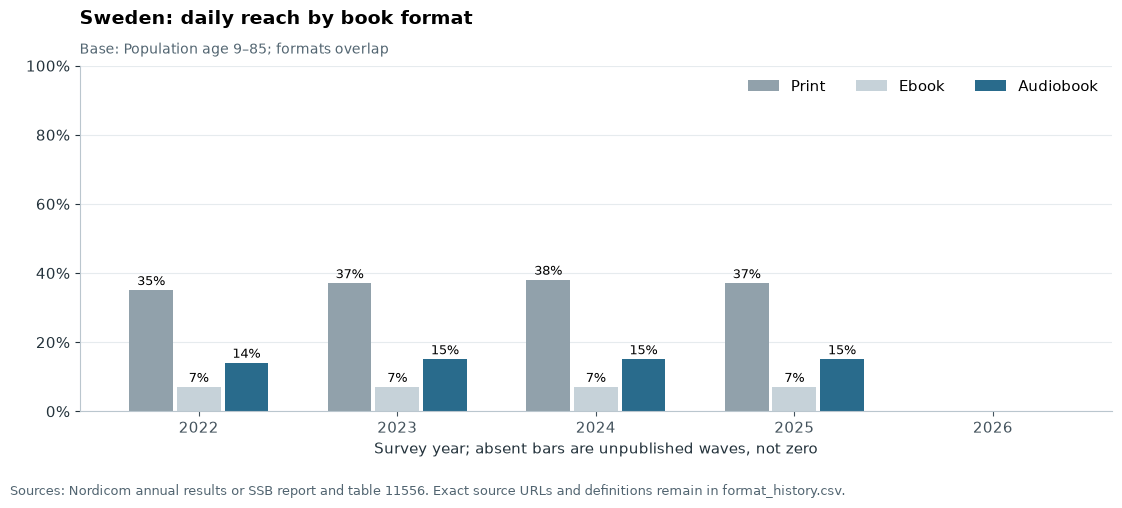

country,year,format_label,participation,denominator,source_url
Sweden,2022,Audiobook,14,Population age 9–85,https://nordicom.gu.se/sv/aktuellt/nyheter/strommad-tv-sociala-medier-dagstidning-sa-anvande-svenskarna-medier-2022
Sweden,2022,Ebook,7,Population age 9–85,https://nordicom.gu.se/sv/aktuellt/nyheter/strommad-tv-sociala-medier-dagstidning-sa-anvande-svenskarna-medier-2022
Sweden,2022,Print,35,Population age 9–85,https://nordicom.gu.se/sv/aktuellt/nyheter/strommad-tv-sociala-medier-dagstidning-sa-anvande-svenskarna-medier-2022
Sweden,2023,Audiobook,15,Population age 9–85,https://nordicom.gu.se/sv/aktuellt/nyheter/rorlig-bild-och-sociala-natverk-mest-populart-sa-anvande-svenskarna-medier-2023
Sweden,2023,Ebook,7,Population age 9–85,https://nordicom.gu.se/sv/aktuellt/nyheter/rorlig-bild-och-sociala-natverk-mest-populart-sa-anvande-svenskarna-medier-2023
Sweden,2023,Print,37,Population age 9–85,https://nordicom.gu.se/sv/aktuellt/nyheter/rorlig-bild-och-sociala-natverk-mest-populart-sa-anvande-svenskarna-medier-2023
Sweden,2024,Audiobook,15,Population age 9–85,https://www.nordicom.gu.se/sv/aktuellt/nyheter/strommat-scrollat-och-last-sa-konsumerade-vi-medier-i-sverige-2024
Sweden,2024,Ebook,7,Population age 9–85,https://www.nordicom.gu.se/sv/aktuellt/nyheter/strommat-scrollat-och-last-sa-konsumerade-vi-medier-i-sverige-2024
Sweden,2024,Print,38,Population age 9–85,https://www.nordicom.gu.se/sv/aktuellt/nyheter/strommat-scrollat-och-last-sa-konsumerade-vi-medier-i-sverige-2024
Sweden,2025,Audiobook,15,Population age 9–85,https://www.nordicom.gu.se/sv/aktuellt/nyheter/youtube-bilradio-och-skonlitteratur-sa-tog-svenskarna-del-av-medier-2025


In [16]:
national_formats = optional_frames.get("format_history")
extra_industry_figures = 0
if national_formats is not None:
    assert not national_formats.duplicated(["country_iso3", "year", "format_label"]).any()
    assert national_formats.participation.dropna().between(0, 100).all()
    FORMAT_HISTORY_COUNTRY = "Sweden"  # Change to "Norway"; preserve each survey's age scope
    national_scope = national_formats[national_formats.country.eq(FORMAT_HISTORY_COUNTRY) & national_formats.year.between(START_YEAR, END_YEAR)].copy()
    assert national_scope.period.nunique() == 1 and national_scope.denominator.nunique() == 1
    fig, ax = plt.subplots(figsize=(11.6, 5.4))
    palette = {"Print": "#91a1ab", "Ebook": "#c6d2d9", "Audiobook": AUDIO_COLOR}
    offsets = {"Print": -0.24, "Ebook": 0.0, "Audiobook": 0.24}
    for label in ["Print", "Ebook", "Audiobook"]:
        series = national_scope[national_scope.format_label.eq(label)].dropna(subset=["participation"])
        ax.bar(series.year + offsets[label], series.participation, width=0.22, color=palette[label], label=label)
        for row in series.itertuples():
            ax.text(row.year + offsets[label], row.participation + 1.5, f"{row.participation:.0f}%", ha="center", fontsize=9)
    ax.set_xticks(range(START_YEAR, END_YEAR + 1))
    ax.set_xlim(START_YEAR - 0.6, END_YEAR + 0.6)
    ax.set_ylim(0, 100)
    ax.yaxis.set_major_formatter(PercentFormatter(100, decimals=0))
    ax.grid(axis="y"); ax.set_axisbelow(True)
    ax.legend(frameon=False, ncol=3, loc="upper right")
    ax.set_title(f"{FORMAT_HISTORY_COUNTRY}: daily reach by book format", loc="left", pad=30)
    ax.text(0, 1.035, f"Base: {national_scope.denominator.iloc[0]}; formats overlap", transform=ax.transAxes, fontsize=10, color="#526571")
    ax.set_xlabel("Survey year; absent bars are unpublished waves, not zero")
    fig.text(0.02, 0.015, "Sources: Nordicom annual results or SSB report and table 11556. Exact source URLs and definitions remain in format_history.csv.", fontsize=9, color="#526571")
    fig.subplots_adjust(left=0.08, right=0.97, top=0.81, bottom=0.17)
    show_figure(fig, "07_paper_ebook_audio_history")
    extra_industry_figures += 1
    readable_table(national_scope[["country", "year", "format_label", "participation", "denominator", "source_url"]], {"year": "{:.0f}", "participation": "{:.0f}"})

### Published book industry sales and revenue

Revenue describes sales value, not the number of readers, listeners or paying subscribers.
Choose one series with its published geography, unit and scope. Do not calculate an audiobook
share by dividing estimates from different associations or incompatible reporting populations.
Amounts come from original releases; later reports revise earlier estimates. Differences between
bars do not establish annual growth or decline. The publication dates and notes remain part of the evidence. Historical WIPO observations describe
2022, with publication year 2023 preserved at year precision. They are not current market estimates.
WIPO already expressed its reported amounts in USD; this project performs no further currency conversion.

**29 country profiles and 42 source-specific monetary series.** Select INDUSTRY_SERIES from the inventory. No values are pooled across currencies or scopes.

country,series_id,metric,unit,first_observation,latest_observation,observations
Austria,aut_wipo_reported_publishing_revenue_2022,Publishing sales and licensing revenue reported to WIPO,USD million,2022,2022,1
Azerbaijan,aze_wipo_reported_publishing_revenue_2022,Trade publishing sales and licensing revenue reported to WIPO,USD million,2022,2022,1
Belgium,bel_wipo_reported_publishing_revenue_2022,French-speaking-region publishing revenue reported to WIPO,USD million,2022,2022,1
Brazil,br_cbl_print_publisher_government_revenue,Printed-book publisher revenue from government sales,BRL million,2024,2025,2
Brazil,br_cbl_print_publisher_market_revenue,Printed-book publisher revenue from market sales,BRL million,2024,2025,2
Brazil,br_cbl_print_publisher_total_revenue,Printed-book publisher revenue including government,BRL million,2024,2025,2
Canada,ca_statcan_book_publishers_operating_revenue,Book publisher operating revenue,CAD million,2022,2024,2
Colombia,col_wipo_reported_publishing_revenue_2022,Publishing sales and licensing revenue reported to WIPO,USD million,2022,2022,1
Czechia,cze_wipo_reported_publishing_revenue_2022,Publishing sales and licensing revenue reported to WIPO,USD million,2022,2022,1
Denmark,dnk_wipo_reported_publishing_revenue_2022,Publishing sales and licensing revenue reported to WIPO,USD million,2022,2022,1


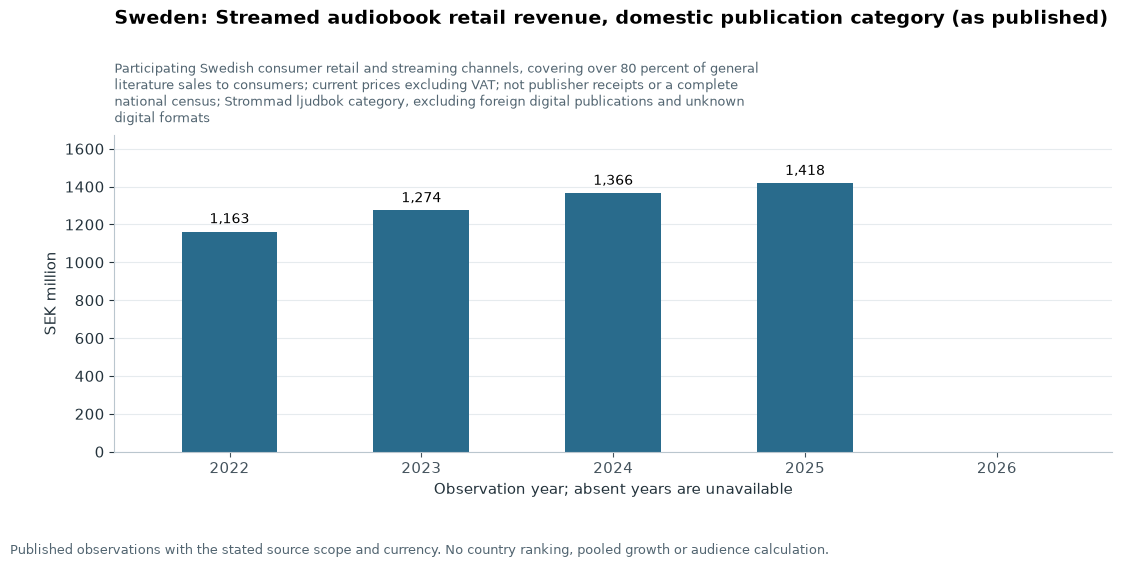

country,year,value,unit,publication_date,notes
Sweden,2022,"1,163.0",SEK million,2026-03-06,"Same Bokforsaljningsstatistiken 2025 report vintage, released 6 March 2026. Original table unit Mkr retained as SEK million. The report revises historical panel data, so do not combine these observations with older report vintages. Independently published rounded totals and format rows are retained without recomputing growth or shares. The streamed categories refer to domestic publication, not all Swedish-language listening. Foreign digital is a combined ebook/audiobook category and is not assigned to either format."
Sweden,2023,"1,274.0",SEK million,2026-03-06,"Same Bokforsaljningsstatistiken 2025 report vintage, released 6 March 2026. Original table unit Mkr retained as SEK million. The report revises historical panel data, so do not combine these observations with older report vintages. Independently published rounded totals and format rows are retained without recomputing growth or shares. The streamed categories refer to domestic publication, not all Swedish-language listening. Foreign digital is a combined ebook/audiobook category and is not assigned to either format."
Sweden,2024,"1,366.0",SEK million,2026-03-06,"Same Bokforsaljningsstatistiken 2025 report vintage, released 6 March 2026. Original table unit Mkr retained as SEK million. The report revises historical panel data, so do not combine these observations with older report vintages. Independently published rounded totals and format rows are retained without recomputing growth or shares. The streamed categories refer to domestic publication, not all Swedish-language listening. Foreign digital is a combined ebook/audiobook category and is not assigned to either format."
Sweden,2025,"1,418.0",SEK million,2026-03-06,"Same Bokforsaljningsstatistiken 2025 report vintage, released 6 March 2026. Original table unit Mkr retained as SEK million. The report revises historical panel data, so do not combine these observations with older report vintages. Independently published rounded totals and format rows are retained without recomputing growth or shares. The streamed categories refer to domestic publication, not all Swedish-language listening. Foreign digital is a combined ebook/audiobook category and is not assigned to either format."


In [17]:
industry = optional_frames.get("industry_metrics")
if industry is not None and not industry.empty:
    assert industry.value.dropna().ge(0).all()
    assert not industry.duplicated(["series_id", "year"]).any()
    audio_series = industry.loc[industry.metric.str.contains("audio", case=False, na=False)].sort_values(["country", "series_id"])
    preferred_series = audio_series.loc[audio_series.country.eq("Sweden"), "series_id"]
    INDUSTRY_SERIES = preferred_series.iloc[0] if not preferred_series.empty else audio_series.series_id.iloc[0]
    inventory = industry.groupby(["country", "series_id", "metric", "unit"], as_index=False).agg(
        first_observation=("year", "min"), latest_observation=("year", "max"), observations=("year", "size"),
    ).sort_values(["country", "series_id"])
    display(Markdown(f"**{industry.country_iso3.nunique()} country profiles and {industry.series_id.nunique()} source-specific monetary series.** Select INDUSTRY_SERIES from the inventory. No values are pooled across currencies or scopes."))
    readable_table(inventory)
    market_series = industry[industry.series_id.eq(INDUSTRY_SERIES) & industry.year.between(START_YEAR, END_YEAR)].sort_values("year")
    assert market_series.unit.nunique() == 1 and market_series.scope.nunique() == 1
    definition = market_series.iloc[0]
    fig, ax = plt.subplots(figsize=(11.6, 6.6))
    ax.bar(market_series.year, market_series.value, width=0.5, color=AUDIO_COLOR)
    for row in market_series.itertuples():
        ax.annotate(f"{row.value:,.0f}", (row.year, row.value), xytext=(0, 6), textcoords="offset points", ha="center", fontsize=10)
    ax.set_xticks(range(START_YEAR, END_YEAR + 1))
    ax.set_xlim(START_YEAR - 0.6, END_YEAR + 0.6)
    ax.set_ylim(0, float(market_series.value.max()) * 1.18)
    ax.set_ylabel(definition.unit)
    ax.set_title(textwrap.fill(f"{definition.country}: {definition.metric} (as published)", 88), loc="left", pad=80)
    ax.text(0, 1.04, textwrap.fill(str(definition.scope), 100), transform=ax.transAxes, fontsize=9, color="#526571")
    ax.grid(axis="y"); ax.set_axisbelow(True)
    ax.set_xlabel("Observation year; absent years are unavailable")
    fig.text(0.02, 0.015, "Published observations with the stated source scope and currency. No country ranking, pooled growth or audience calculation.", fontsize=9, color="#526571")
    fig.subplots_adjust(left=0.11, right=0.97, top=0.65, bottom=0.17)
    show_figure(fig, "08_industry_market_revenue")
    extra_industry_figures += 1
    readable_table(market_series[["country", "year", "value", "unit", "publication_date", "notes"]], {"year": "{:.0f}", "value": "{:,.1f}"})

### Company and platform coverage

The reviewed register includes audiobook services, print publishers, retailers and library
platforms. Brand, parent, availability and reporting scope have separate meanings. A service's
availability does not establish its national subscriber count. Blank or unextracted metrics remain
missing. Company reporting can cover several formats or business divisions.

In [18]:
companies = optional_frames.get("companies")
if companies is not None:
    assert companies.company_id.is_unique
    assert companies.source_url.str.startswith("https://").all()
    display(Markdown(f"**{len(companies)} reviewed company/platform records.** This initial inventory is not an exhaustive company census."))
    readable_table(companies[["company", "parent_company", "formats", "business_model", "public_data_status"]])
    readable_table(companies[["company", "geographic_scope", "source_url", "reviewed_on", "notes"]])

**23 reviewed company/platform records.** This initial inventory is not an exhaustive company census.

company,parent_company,formats,business_model,public_data_status
Amazon books / Kindle / KDP,Not published,Print; Ebook,Book retail marketplace; ebook subscription; self-publishing and print on demand,Public reporting documented
Spotify,Not published,Audiobook; Print,Premium audiobook listening allowances; audiobook purchases and add-ons; print referral commerce,Public reporting documented
Apple Books,Apple Inc.,Ebook; Audiobook,Individual digital book purchases,Public service information documented
Google Play Books,Google,Ebook; Audiobook,Individual digital book purchases; publisher distribution,Public service information documented
Rakuten Kobo,"Rakuten Group, Inc.",Ebook; Audiobook,Digital book retail; Kobo Plus subscription in eligible markets; reading devices,Public reporting documented
Everand,"Scribd, Inc.",Ebook; Audiobook,Subscription with plan-specific premium title unlocks and a separate unlimited catalogue,Public service information documented
BookBeat,Bonnier Books (Bonnier Group),Ebook; Audiobook,Book streaming subscription,Public reporting documented
Storytel Group,Not published,Print; Ebook; Audiobook,Book streaming subscriptions; publishing and distribution,Public reporting documented
Audiobooks.com,Storytel Group,Audiobook,Audiobook subscription; individual title purchases,Public service information documented
Mofibo,Storytel Group,Ebook; Audiobook,Book streaming subscription,Public service information documented


company,geographic_scope,source_url,reviewed_on,notes
Amazon books / Kindle / KDP,International Amazon marketplaces; title and programme availability varies by territory,https://ir.aboutamazon.com/annual-reports-proxies-and-shareholder-letters/default.aspx,2026-10-08,Parent-level reporting covers many businesses. Book-specific revenues and subscribers were not extracted. Audible is listed separately; these rows must not be summed.
Spotify,Audiobooks in selected markets; wider rollout announced for completion by end of 2026; print purchases via partner in US and UK,https://investors.spotify.com/financials/default.aspx,2026-10-08,"Print means purchases through Bookshop.org, not a Spotify-owned print catalogue. The 7 October 2026 global expansion announcement is a rollout plan, not proof all announced markets are live. Group music and podcast metrics are not audiobook metrics."
Apple Books,Supported countries and regions; ebooks and audiobooks have different availability lists,https://www.apple.com/apple-books/,2026-10-08,"Official Apple service information documents ebooks and audiobooks. No book-specific subscribers, sales or revenue were extracted; Apple-wide figures are not a substitute."
Google Play Books,Supported countries and territories; sale eligibility and format availability vary,https://support.google.com/books/partner/table/6052428?hl=en,2026-10-08,"Official table distinguishes purchase, publisher signup and payment eligibility. These are not identical market-presence measures. No book-specific usage or revenue metric was extracted."
Rakuten Kobo,International digital retail; audiobook and Kobo Plus eligibility varies by country,https://global.rakuten.com/corp/investors/assets/doc/documents/ar_2024_all.pdf,2026-10-08,Rakuten parent reporting documents the Kobo business. Reading devices are not print book consumption. Kobo-specific subscriber or format revenue metrics were not extracted.
Everand,International digital service; territorial catalogue and plan availability require separate review,https://www.everand.com/,2026-10-08,"Everand is the book service within Scribd, Inc.; Scribd's document platform is a different service. Do not treat combined platform users as book readers or audiobook subscribers. No comparable metrics were extracted."
BookBeat,"European markets, including Nordic and continental European storefronts",https://bonnierbooks.com/our-businesses/bookbeat/,2026-10-08,"The parent publishes a BookBeat business overview and reporting. Subscriber definitions, dates and country scope require metric-by-metric extraction before comparison. No quantities were imported into this register."
Storytel Group,Selected international streaming markets and regional publishing businesses,https://www.storytelgroup.com/en/business-areas/streaming/,2026-10-08,"Group row includes Storytel, Mofibo and Audiobooks.com streaming brands plus publishing. Brand rows overlap this group and cannot be summed with group metrics. Public group and segment reporting requires matching metric scope."
Audiobooks.com,North American service with international access subject to publisher territorial restrictions,https://www.audiobooks.com/faqs,2026-10-08,Storytel's official streaming page lists this brand. International availability is not evidence of a separately operated local country market. Group subscribers are not an Audiobooks.com-only metric.
Mofibo,Denmark verified through official Danish storefront,https://mofibo.com/dk,2026-10-08,Storytel's official streaming page lists Mofibo. Brand geography is distinct from Storytel Group's international footprint. No Mofibo-only subscriber or revenue series was extracted.


## Takeaways

1. **Start with the right audio question.** For addressable demand, obtain annual audiobook
   participation among a defined adult population. Daily reach and reader-subset listening are
   useful profiles, but cannot replace that denominator.
2. **Keep new entry and existing-market growth separate.** Canada has format-specific
   audio genres; the US has consistent historical adoption evidence; Singapore has an annual
   e-audiobook observation within a reader subset. These strengths inform what can be studied next.
   Verify brand and group presence before assigning an entry track. Use local acquisition,
   retention and catalogue evidence for existing-market growth. The notebook cannot establish an investment winner.
3. **Use Nordic daily reach as an operating benchmark.** Sweden and Norway demonstrate measured
   daily listening within their stated age populations. Compare future extracts within a matched
   scope before making a ranking.
4. **Turn selected-year Canadian genres into testable catalogue questions.** Keep `GENRE_YEAR`
   and the calculated fiction/nonfiction leaders visible. Check local rights, language fit, title breadth, listening
   hours, completion, acquisition and retention before treating those selections as catalogue ROI.
   The 2026 common-question listener data supplies further genre and occasion hypotheses across
   five existing markets. Its unreported top-five categories remain unknown.
5. **Close the decision gaps before investment.** Verify Storytel's current presence and entry
   constraints. Add local audiobook paid penetration, price willingness, competitor share,
   acquisition cost, retention and contribution margin from governed sources or direct research.

**Next useful analysis:** a source-matched candidate-country demand study plus a unit-economics
scenario using verified business inputs. Keep assumptions, denominators and sensitivity ranges visible.

### Sources and reproducibility receipt

Source links point to the original publisher documents used in the cached evidence. Full input
hashes identify this notebook run. They detect file changes, rather than certifying survey quality.
Shared row equality above ensures this notebook and the current dashboard describe the same data.

In [19]:
source_table = pd.concat([formats, profile_data, audio_profiles, canada_audio, refreshed_genres, refreshed_audio], ignore_index=True)[["country", "year", "source_id", "source_url", "evidence_locator"]].drop_duplicates().sort_values(["country", "year"])
if storytel is not None:
    source_table = pd.concat([source_table, pd.DataFrame([{
        "country": "Five common-question markets", "year": 2026, "source_id": "storytel_story_report_2026",
        "source_url": storytel.source_url.iloc[0], "evidence_locator": "2026 report pp.13–14; listener occasions and genres",
    }])], ignore_index=True)
source_table["Original source"] = source_table.source_url.map(lambda url: f'<a href="{url}" target="_blank">Publisher document</a>')
source_html = source_table[["country", "year", "source_id", "Original source", "evidence_locator"]].rename(columns={
    "country": "Country", "year": "Survey year", "source_id": "Source ID", "evidence_locator": "Evidence locator",
}).to_html(index=False, escape=False)
display(HTML(source_html))
input_paths = [ROOT / "data/processed" / filename for filename in FILES.values()]
input_paths += [ROOT / "data/processed/dashboard_snapshot.json", ROOT / "data/curated/source_checks.json"]
input_paths += [ROOT / "data/processed" / OPTIONAL_FILES[query] for query in optional_frames]
if research_metadata_path.is_file():
    input_paths.append(research_metadata_path)
receipt = pd.DataFrame([{
    "Input": path.relative_to(ROOT).as_posix(),
    "SHA-256": hashlib.sha256(path.read_bytes()).hexdigest(),
} for path in input_paths])
readable_table(receipt)
package_versions = {name: version(name) for name in ["pandas", "numpy", "matplotlib", "nbformat", "nbclient"]}
readable_table(pd.DataFrame([package_versions]))
expected_figures = ((4 if not selected_audio.empty else 3) + int(history_figure_created)
                    + int(storytel_genre_figure_created) + int(storytel_moment_figure_created))
expected_figures += extra_industry_figures + 2
assert len(figure_paths) == expected_figures
assert all(path.is_file() and path.stat().st_size > 10_000 for path in figure_paths)
assert not selected_audio.period.isna().any()
display(Markdown(f"**Run complete:** all input, metric and dashboard-row checks passed. "
                 f"{len(figure_paths)} native analytical figures were retained inline and saved in `outputs/audiobook_figures/`. "
                 "Commercial, comparability and survey-design limitations remain as stated above."))

Country,Survey year,Source ID,Original source,Evidence locator
Australia,2022,creative_au,Publisher document,"Printed p.173 (PDF index 174), Figure 59, Australians engagement with books by year; exact question and both wave n below figure; methods pp.16-19"
Australia,2022,creative_au,Publisher document,"Printed p.175 (PDF index 176), explicit Of all Australians format percentages; methods pp.16-19 (PDF indices 17-20)"
Australia,2025,creative_au,Publisher document,"Printed p.175 (PDF index 176), explicit Of all Australians format percentages; methods pp.16-19 (PDF indices 17-20)"
Australia,2025,creative_au,Publisher document,"Printed p.173 (PDF index 174), Figure 59, Australians engagement with books by year; exact question and both wave n below figure; methods pp.16-19"
Canada,2024,booknet_ca,Publisher document,Format preferences and frequency of reading
Canada,2024,booknet_ca,Publisher document,Printed p.32; Fiction genres read by format
Canada,2024,booknet_ca,Publisher document,Printed p.33; Non-fiction subjects read by format
Canada,2025,booknet_ca,Publisher document,"Printed p.25 (PDF index 24), readership prose and Reading frequency by format table; methodology p.4; Appendix A Q33"
Canada,2025,booknet_ca,Publisher document,"Printed p.25 (PDF index 24), readership prose and Reading frequency by format table; methodology p.4; Appendix A Q23"
Canada,2025,booknet_ca,Publisher document,"Printed p.25 (PDF index 24), readership prose and Reading frequency by format table; methodology p.4; Appendix A Q45"


Input,SHA-256
data/processed/format_profiles.csv,14fbb92e0680a5abecdd30747b3656b1cd4b8d57d0753efe6f9a3298ba69c2d1
data/processed/us_formats.csv,b2677fe52959707555bb86e58418f6c80f0925d25160eefea1e5f00029b7bcba
data/processed/genre_profiles.csv,28f2f04f260f1b51c7ba920d8762a3ce8edd4581010e7c023669b3c9ac778dba
data/processed/dashboard_snapshot.json,e6378ba260ec3de821f87bcd32ef6562fb80ef4cd71805874adf4437a4a211ea
data/curated/source_checks.json,e322701fda39e775ad675a683ae93e769f9d63cd0aee8067ba8b606b7c25336b
data/processed/audiobook_history.csv,2e3337c932036cbad192b89a8e632880255d7ddc1cfe9d42e4c7a760514e67cf
data/processed/audio_market_evidence.csv,150263a23fd77b9df4d70e3ae1d9befe83a82c5df4326a008d47572054f43d15
data/processed/data_freshness.csv,7efae86e9054eea7ebe1418b1460f548e0bd440f1c2160fe63c10d29bcbb2373
data/processed/format_history.csv,30657dcc376b4d51c69253b55ce8e22915292c42f0a218590d655cc87903171b
data/processed/genre_history.csv,d574915688ccc2af3742bfa0aaff15a23d7d4ef68e08b7a9c59656709686df43


pandas,numpy,matplotlib,nbformat,nbclient
3.0.6,2.5.4,3.11.2,5.11.1,0.11.0


**Run complete:** all input, metric and dashboard-row checks passed. 11 native analytical figures were retained inline and saved in `outputs/audiobook_figures/`. Commercial, comparability and survey-design limitations remain as stated above.